# Assignment:02 ANN & Deep Learning
### Resnet and Unet

| | |
|---|---|
| **Name** | ____Anas__________________________ |
| **Roll No.** | ____BSCS23190__________________________ |

---


>
> **Grading (100 marks)**
>
> | Part | Marks |
> |---|---:|
> | Dataset setup, exploration, preprocessing, split (Tasks 1-4, 12-14) | 20 |
> | ResNet-50 modification, training and evaluation (Tasks 5-11) | 25 |
> | U-Net loss, metrics, training and evaluation (Tasks 15-20) | 25 |
> | Results tables (Task 21) and filled-in reports | 5 |
> | Discussion questions and conclusion | 15 |
> | GitHub repository, README, code quality / comments | 10 |

# Table of Contents
1. Introduction
2. Learning Objectives
3. Datasets - where to download them and how to upload them to Google Drive
4. **Step 1** - Environment setup (libraries, GPU, reproducibility)
5. **Step 2** - Mount Google Drive and set the dataset paths
6. **Part A - ResNet-50 Fine-Tuning (Classification)**
    * Step 3 - Explore the flower dataset
    * Step 4 - Preprocessing, augmentation and train/validation/test split
    * Step 5 - ResNet-50 architecture and loading the pretrained model
    * Step 6 - Training utilities
    * Step 7 - Phase 1: feature extraction (frozen backbone)
    * Step 8 - Phase 2: fine-tuning (unfreeze `layer4`)
    * Step 9 - Training curves
    * Step 10 - Evaluation on the test set
7. **Part B - U-Net Fine-Tuning (Segmentation)**
    * Step 11 - Explore the pet segmentation dataset
    * Step 12 - Joint image/mask preprocessing, split and loaders
    * Step 13 - U-Net architecture and model creation
    * Step 14 - Loss function and metrics
    * Step 15 - Phase 1: train the decoder (frozen encoder)
    * Step 16 - Phase 2: fine-tune the encoder
    * Step 17 - Evaluation and visualization






# Introduction
Training a deep convolutional network from scratch needs **tens of thousands of labelled images** and a lot of compute. In practice (medical imaging, agriculture, small company datasets) we often have only **100-200 images**. In such cases we rely on **transfer learning**: we start from a network that was already trained on a very large dataset (ImageNet, 1.2 million images) and **adapt** it to our own small dataset. This adaptation step is called **fine-tuning**.

In this assignment you will fine-tune two of the most important CNN families in computer vision:

| Model | Task | Idea |
|---|---|---|
| **ResNet-50** | Image **classification** (what is in the image?) | Deep CNN with *residual (skip) connections* and bottleneck blocks |
| **U-Net** (with a ResNet-50 encoder) | Image **segmentation** (which pixels belong to the object?) | Encoder-decoder network with *skip connections* between encoder and decoder |



# Datasets (Download -> Upload to Google Drive)

Use **two small datasets** (about **100-200 images** each).

| | Dataset 1 (classification) | Dataset 2 (segmentation) |
|---|---|---|
| **Name** | Oxford Flowers-102 (small subset) | Oxford-IIIT Pet (small subset) |
| **Official page / download** | https://www.robots.ox.ac.uk/~vgg/data/flowers/102/ | https://www.robots.ox.ac.uk/~vgg/data/pets/ |
| **Files** | `102flowers.tgz`, `imagelabels.mat` | `images.tar.gz`, `annotations.tar.gz` |
| **Size to use** | 5 classes x 40 images = **200 images** | **150 image + mask pairs** |
| **Used by** | ResNet-50 | U-Net |


### Required folder structure on Google Drive
```text
MyDrive/
└── ANN_DL_Assignment/
    ├── flowers_subset/              <- classification dataset (ImageFolder format)
    │   ├── flower_class_000/  *.jpg
    │   ├── flower_class_001/  *.jpg
    │   └── ...
    └── pets_subset/                 <- segmentation dataset
        ├── images/   *.jpg
        └── masks/    *.png          <- same file name as the image
```
For the pet masks, the original *trimap* convention is kept: `1 = pet`, `2 = background`, `3 = border`.


# Step 1: Environment Setup
**Before running:** in Colab choose **Runtime -> Change runtime type -> T4 GPU**. Training ResNet-50 and U-Net on a CPU is very slow.

We install `segmentation-models-pytorch` (SMP), which provides U-Net with pretrained encoders, and import all libraries. We also fix the random seeds so that results are **reproducible**.

In [1]:
# Install the segmentation library (U-Net with pretrained encoders)
!pip install -q segmentation-models-pytorch

In [2]:
# ---------------- Standard libraries ----------------
import os, random, shutil, copy, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

# ---------------- PyTorch ----------------
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader, Subset
from torchvision import datasets, models, transforms
import torchvision.transforms.functional as TF

# ---------------- Scikit-learn (splitting + metrics) ----------------
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay,
                             precision_recall_fscore_support)

# ---------------- U-Net library ----------------
import segmentation_models_pytorch as smp

# ---------------- Reproducibility ----------------
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

# ---------------- Device ----------------
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch version :", torch.__version__)
print("Using device    :", device)
if device.type == "cpu":
    print("WARNING: no GPU found. Go to Runtime > Change runtime type > T4 GPU.")



PyTorch version : 2.11.0+cu130
Using device    : cuda


In [3]:
# ImageNet statistics: pretrained models expect inputs normalized with them
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD  = [0.229, 0.224, 0.225]

# Step 2: Mount Google Drive and Set Paths
Colab's local disk is erased when the runtime restarts. **Google Drive** keeps the datasets and trained models permanently. After running the cell below, Google asks for permission to access your Drive - click **Allow**.

In [4]:
from google.colab import drive

# Mount Google Drive at /content/drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [28]:
BASE_DIR     = "/content/drive/MyDrive/ann"      # main assignment folder on Drive
FLOWERS_DIR  = os.path.join(BASE_DIR, "102_flowers_dataset")    # classification dataset
PETS_DIR     = os.path.join(BASE_DIR, "oxford-iiit-pet")       # segmentation dataset

# Oxford Pet dataset archives
PET_IMG_ARCHIVE = os.path.join(PETS_DIR, "images.tar.gz")
PET_ANN_ARCHIVE = os.path.join(PETS_DIR, "annotations.tar.gz")
# Oxford Flowers dataset archives
FLOWERS_ARCHIVE = os.path.join(FLOWERS_DIR, "102flowers.tgz")
FLOWERS_SEG_ARCHIVE = os.path.join(FLOWERS_DIR, "102segmentations.tgz")
# Extracted Oxford Pet images and masks
PET_IMG_DIR = os.path.join(PETS_DIR, "images")
PET_MASK_DIR = os.path.join(PETS_DIR, "annotations", "trimaps")
# Save trained models and results
CKPT_DIR = os.path.join(BASE_DIR, "checkpoints")
RESULTS_DIR = "/content/results"

print("Flowers folder exists:", os.path.isdir(FLOWERS_DIR))
print("Pets folder exists:", os.path.isdir(PETS_DIR))
print("Flowers archive exists:", os.path.isfile(FLOWERS_ARCHIVE))
print("Pet images archive exists:", os.path.isfile(PET_IMG_ARCHIVE))
print("Pet annotations archive exists:", os.path.isfile(PET_ANN_ARCHIVE))
for d in [BASE_DIR, CKPT_DIR, RESULTS_DIR]:
    os.makedirs(d, exist_ok=True)
print("Base folder exists:", os.path.isdir(BASE_DIR))

Flowers folder exists: True
Pets folder exists: True
Flowers archive exists: True
Pet images archive exists: True
Pet annotations archive exists: True
Base folder exists: True


---
# PART A - ResNet-50 Fine-Tuning (Classification)
---
# Step 3: Explore the Flower Dataset
Always inspect your data before training: how many images, how many classes, is the dataset balanced, what do images look like, and what sizes do they have?

### Task 1 — Count and plot the images (Step 3)
Complete the cell below.

1. **(1a)** Fill the dictionary `counts` so that it maps each class folder name to its number of images. *Hint:* `os.listdir(os.path.join(FLOWERS_DIR, c))` lists the files of class `c`.
2. **(1b)** Print the number of classes, the total number of images, and the images per class.
3. **(1c)** Draw a bar chart of the class distribution with `plt.bar`.

**Report:** number of classes = ______ , total number of images = ______

In [6]:
import scipy.io
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image


Selected classes: [51 77 46 73 89]
Number of classes: 5
Total selected images: 1083
Class 51: 258 images
Class 77: 251 images
Class 46: 196 images
Class 73: 194 images
Class 89: 184 images


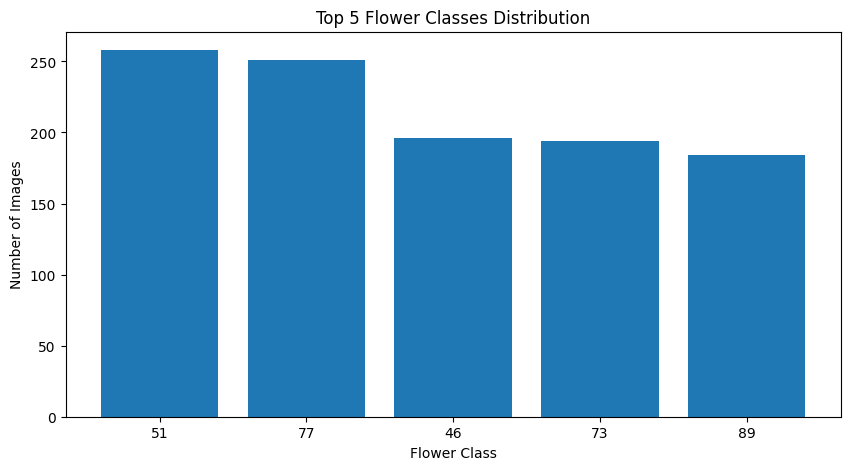

In [29]:
labels_path = "/content/drive/MyDrive/ann/102_flowers_dataset/imagelabels.mat"

labels = scipy.io.loadmat(labels_path)["labels"].flatten()

# Count images per class
classes, counts = np.unique(labels, return_counts=True)

# Select top 5 classes with most images
top_indices = np.argsort(-counts, kind="stable")[:5]

top5_classes = classes[top_indices]
top5_counts = counts[top_indices]

print("Selected classes:", top5_classes)
print("Number of classes:", len(top5_classes))
print("Total selected images:", sum(top5_counts))

for c, count in zip(top5_classes, top5_counts):
    print(f"Class {c}: {count} images")

# Plot top 5 class distribution
plt.figure(figsize=(10, 5))
plt.bar(top5_classes.astype(str), top5_counts)
plt.xlabel("Flower Class")
plt.ylabel("Number of Images")
plt.title("Top 5 Flower Classes Distribution")
plt.show()

### Task 2 — Show one sample per class (Step 3)
For every class display **one image** with its **class name** and **size (width x height)** in the title.
*Hint:* `Image.open(path).convert("RGB")` gives a PIL image; `img.size` gives `(width, height)`.

In [30]:
import os
import tarfile

# Location of compressed dataset in Google Drive
archive_path = "/content/drive/MyDrive/ann/102_flowers_dataset/102flowers.tgz"

extract_path = "/content/datasets/flowers"

os.makedirs(extract_path, exist_ok=True)

print("Archive exists:", os.path.isfile(archive_path))

# Extract the images
with tarfile.open(archive_path, "r:gz") as tar:
    tar.extractall(path=extract_path, filter="data")

print("Extraction completed!")

Archive exists: True
Extraction completed!


Images found in: /content/datasets/flowers/jpg


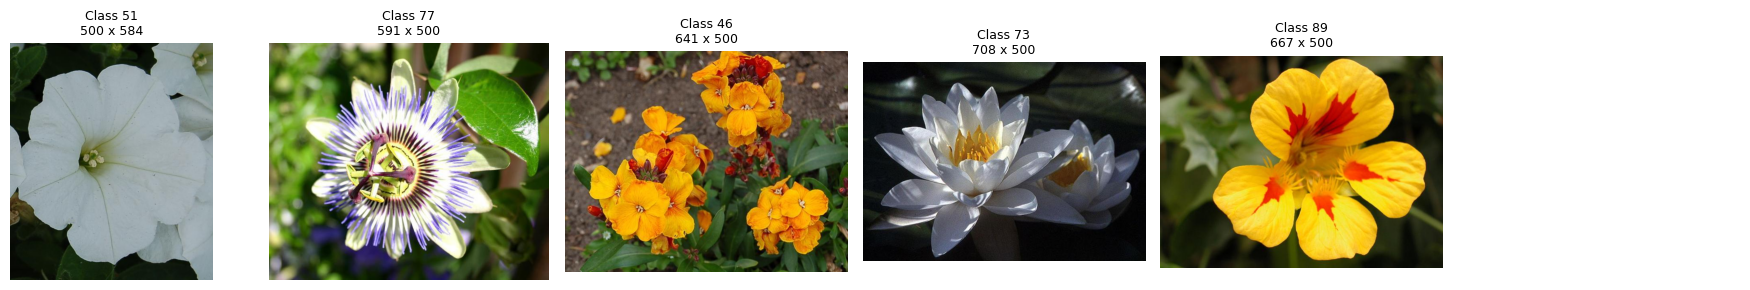

In [31]:
labels_path = "/content/drive/MyDrive/ann/102_flowers_dataset/imagelabels.mat"
labels = scipy.io.loadmat(labels_path)["labels"].flatten()

# Find extracted flower images
FLOWERS_IMG_DIR = None

for root, dirs, files in os.walk("/content/datasets/flowers"):
    if "image_00001.jpg" in files:
        FLOWERS_IMG_DIR = root
        break

if FLOWERS_IMG_DIR is None:
    raise FileNotFoundError(
        "Flower images not found. Extract 102flowers.tgz first."
    )

print("Images found in:", FLOWERS_IMG_DIR)

# Get unique classes
classes = top5_classes

# Create a grid (6 images per row)
cols = 6
rows = int(np.ceil(len(classes) / cols))

fig, axes = plt.subplots(rows, cols, figsize=(18, rows * 3))
axes = np.atleast_1d(axes).flatten()

# Show one image for each class
for ax, c in zip(axes, classes):

    # 1. Find the first image belonging to class c
    image_index = np.where(labels == c)[0][0]

    # 2. Construct the image filename
    filename = f"image_{image_index + 1:05d}.jpg"

    # 3. Open the image and convert it to RGB
    image_path = os.path.join(FLOWERS_IMG_DIR, filename)
    img = Image.open(image_path).convert("RGB")

    # 4. Get image dimensions
    width, height = img.size

    # 5. Display the image
    ax.imshow(img)

    # 6. Set title (class name + dimensions)
    ax.set_title(f"Class {c}\n{width} x {height}", fontsize=9)

    # 7. Hide axis ticks
    ax.axis("off")

for ax in axes[len(classes):]:
    ax.axis("off")

plt.tight_layout()
plt.show()

# Step 4: Preprocessing, Augmentation and Data Split

### Why preprocessing?
```text
Original image -> Resize (224x224) -> Augmentation (train only) -> ToTensor -> Normalize (ImageNet mean/std) -> Model
```
* **Resize:** a CNN with a fixed classifier needs a fixed input size (224x224 for ResNet).
* **Augmentation:** random flips/rotations/colour changes create "new" images every epoch. This is the most important regulariser for small datasets. **Never augment validation/test images**, otherwise evaluation becomes noisy.
* **Normalization:** pretrained weights were learned with ImageNet-normalized inputs, so we must use the same mean/std.

### Data split (stratified)
```text
70% Training   -> the model learns from it
15% Validation -> monitor overfitting, pick the best epoch / hyper-parameters
15% Test       -> used ONCE at the end for the final, unbiased score
```
*Stratified* means every class keeps the same proportion in each subset.

### Task 3 — Build the transformation pipelines (Step 4)
Complete `train_tf` with **four** parts, in this order, and `eval_tf` **without augmentation**:

| Part | Transform | Notes |
|---|---|---|
| 1 | Resize | to `(IMG_SIZE, IMG_SIZE)` |
| 2 | Augmentation | random horizontal flip, random rotation (15 degrees), colour jitter (brightness/contrast/saturation 0.2) |
| 3 | Tensor | `transforms.ToTensor()` |
| 4 | Normalize | with `IMAGENET_MEAN`, `IMAGENET_STD` |

*Question to think about:* why must `eval_tf` not contain random augmentation?

In [10]:
from torchvision import transforms

In [33]:
IMG_SIZE = 224



# ImageNet normalization values
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

# Training transformations
train_tf = transforms.Compose([

    # 1. Resize images to 224 x 224
    transforms.Resize((IMG_SIZE, IMG_SIZE)),

    # 2. Random augmentation
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ColorJitter(
        brightness=0.2,
        contrast=0.2,
        saturation=0.2
    ),

    # 3. Convert image to PyTorch tensor
    transforms.ToTensor(),

    # 4. Normalize using ImageNet mean and std
    transforms.Normalize(
        mean=IMAGENET_MEAN,
        std=IMAGENET_STD
    )
])

# Evaluation transformations (NO augmentation)
eval_tf = transforms.Compose([

    transforms.Resize((IMG_SIZE, IMG_SIZE)),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=IMAGENET_MEAN,
        std=IMAGENET_STD
    )
])

print("Training transformations:", train_tf)
print("Evaluation transformations:", eval_tf)

Training transformations: Compose(
    Resize(size=(224, 224), interpolation=bilinear, max_size=None, antialias=True)
    RandomHorizontalFlip(p=0.5)
    RandomRotation(degrees=[-15.0, 15.0], interpolation=nearest, expand=False, fill=0)
    ColorJitter(brightness=(0.8, 1.2), contrast=(0.8, 1.2), saturation=(0.8, 1.2), hue=None)
    ToTensor()
    Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
)
Evaluation transformations: Compose(
    Resize(size=(224, 224), interpolation=bilinear, max_size=None, antialias=True)
    ToTensor()
    Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
)


### Task 4 — Stratified 70/15/15 split and DataLoaders (Step 4)
The two `ImageFolder` objects point to the **same files**: one applies augmentation (`train_tf`), the other does not (`eval_tf`). Complete the following:

* **(4a)** Split the **indices** with `train_test_split` (called twice): 70% train / 30% temp, then split temp 50/50 into validation and test. Use `stratify=` and `random_state=SEED` so every class keeps its proportion.
* **(4b)** Create the four `Subset` objects: `train_ds` (augmented), `train_eval_ds` (train indices but *without* augmentation, used only to measure training accuracy), `val_ds`, `test_ds`.
* **(4c)** Create the four `DataLoader`s (`BATCH = 16`): `train_loader` (shuffle=True), `train_eval_loader`, `val_loader`, `test_loader` (shuffle=False, `num_workers=2`).
* Print the size of each subset.

In [36]:
SEED = 42
BATCH = 16

# -------------------------------------------
# Select top 5 flower classes
# -------------------------------------------

# Uses top5_classes from Task 1
selected_indices = np.where(
    np.isin(labels, top5_classes)
)[0]

# Map original class labels to 0, 1, 2, 3, 4
label_mapping = {
    int(c): i for i, c in enumerate(top5_classes)
}


# -------------------------------------------
# Custom Oxford Flowers Dataset
# -------------------------------------------

class FlowersDataset(Dataset):

    def __init__(self, image_dir, labels, indices, transform=None):
        self.image_dir = image_dir
        self.labels = np.asarray(labels).flatten()
        self.indices = np.asarray(indices)
        self.transform = transform

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, idx):

        # Get original image index
        original_idx = int(self.indices[idx])

        # Construct original image filename
        filename = f"image_{original_idx + 1:05d}.jpg"
        image_path = os.path.join(self.image_dir, filename)

        # Load image
        image = Image.open(image_path).convert("RGB")

        # Remap label to 0-4
        original_label = int(self.labels[original_idx])
        label = label_mapping[original_label]

        # Apply transformations
        if self.transform:
            image = self.transform(image)

        return image, label


# -------------------------------------------
# Create datasets
# -------------------------------------------

full_train = FlowersDataset(
    FLOWERS_IMG_DIR,
    labels,
    selected_indices,
    transform=train_tf
)

full_eval = FlowersDataset(
    FLOWERS_IMG_DIR,
    labels,
    selected_indices,
    transform=eval_tf
)


# -------------------------------------------
# Class names and targets
# -------------------------------------------

class_names = [
    f"flower_class_{c:03d}" for c in top5_classes
]

num_classes = len(top5_classes)

targets = np.array([
    label_mapping[int(labels[i])]
    for i in selected_indices
])

all_idx = np.arange(len(targets))

print("Number of selected classes:", num_classes)
print("Total selected images:", len(all_idx))
print("Selected class names:", class_names)


# -------------------------------------------
# (4a) Stratified 70/15/15 split
# -------------------------------------------

train_idx, temp_idx = train_test_split(
    all_idx,
    test_size=0.30,
    random_state=SEED,
    stratify=targets
)

val_idx, test_idx = train_test_split(
    temp_idx,
    test_size=0.50,
    random_state=SEED,
    stratify=targets[temp_idx]
)


# -------------------------------------------
# (4b) Create four Subset objects
# -------------------------------------------

train_ds = Subset(full_train, train_idx)

train_eval_ds = Subset(full_eval, train_idx)

val_ds = Subset(full_eval, val_idx)

test_ds = Subset(full_eval, test_idx)


# -------------------------------------------
# (4c) Create four DataLoaders
# -------------------------------------------

train_loader = DataLoader(
    train_ds,
    batch_size=BATCH,
    shuffle=True,
    num_workers=2
)

train_eval_loader = DataLoader(
    train_eval_ds,
    batch_size=BATCH,
    shuffle=False,
    num_workers=2
)

val_loader = DataLoader(
    val_ds,
    batch_size=BATCH,
    shuffle=False,
    num_workers=2
)

test_loader = DataLoader(
    test_ds,
    batch_size=BATCH,
    shuffle=False,
    num_workers=2
)


# -------------------------------------------
# Print dataset statistics
# -------------------------------------------

print("\nDataset Split:")
print("Training:", len(train_ds))
print("Training evaluation:", len(train_eval_ds))
print("Validation:", len(val_ds))
print("Testing:", len(test_ds))

print("\nClass Mapping:")
for original, new in label_mapping.items():
    print(f"Original Class {original} -> New Class {new}")

Number of selected classes: 5
Total selected images: 1083
Selected class names: ['flower_class_051', 'flower_class_077', 'flower_class_046', 'flower_class_073', 'flower_class_089']

Dataset Split:
Training: 758
Training evaluation: 758
Validation: 162
Testing: 163

Class Mapping:
Original Class 51 -> New Class 0
Original Class 77 -> New Class 1
Original Class 46 -> New Class 2
Original Class 73 -> New Class 3
Original Class 89 -> New Class 4


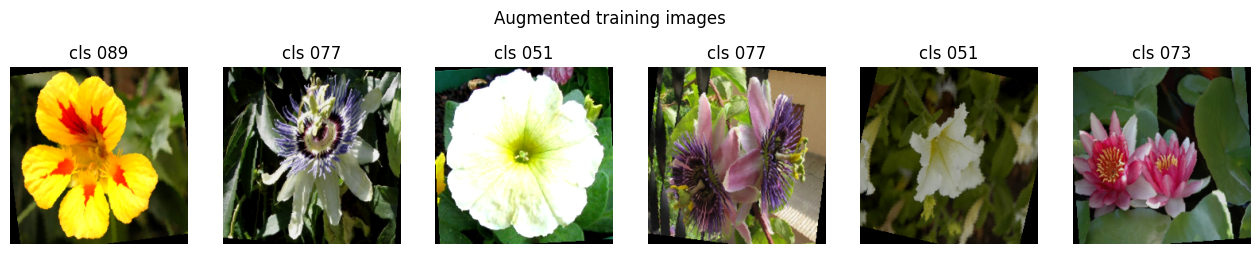

In [37]:
# ---- Visualize augmented training samples ----
MEAN_T = torch.tensor(IMAGENET_MEAN).view(3, 1, 1)
STD_T  = torch.tensor(IMAGENET_STD).view(3, 1, 1)

def denorm(t):
    # Undo ImageNet normalization so that a tensor can be displayed.
    return (t.cpu() * STD_T + MEAN_T).clamp(0, 1).permute(1, 2, 0).numpy()

imgs, labels = next(iter(train_loader))
fig, axes = plt.subplots(1, 6, figsize=(16, 3))
for ax, im, lb in zip(axes, imgs[:6], labels[:6]):
    ax.imshow(denorm(im)); ax.set_title(class_names[lb].replace("flower_class_", "cls ")); ax.axis("off")
plt.suptitle("Augmented training images"); plt.show()

# Step 5: ResNet-50 Architecture and Pretrained Model

### Why residual connections?
Very deep plain CNNs become *harder* to train (vanishing gradients, the "degradation problem"). ResNet adds a **skip (identity) connection** so each block learns a *residual* `F(x)` and outputs `F(x) + x`. Gradients flow directly through the shortcut, which makes networks with 50, 101 or 152 layers trainable.

### ResNet-50 overview
```text
Input 224x224x3
   |
7x7 Conv, stride 2 + BatchNorm + ReLU + 3x3 MaxPool
   |
layer1 : 3  bottleneck blocks   (256  channels)
layer2 : 4  bottleneck blocks   (512  channels)
layer3 : 6  bottleneck blocks   (1024 channels)
layer4 : 3  bottleneck blocks   (2048 channels)
   |
Global Average Pooling
   |
Fully connected (fc): 2048 -> 1000 (ImageNet)   <-- we REPLACE this layer
```

### Bottleneck residual block (used by ResNet-50)
```text
x ──────────────────────────────┐   (skip connection; 1x1 conv if shape changes)
│                               │
1x1 Conv (reduce channels) + BN + ReLU
│                               │
3x3 Conv                    + BN + ReLU
│                               │
1x1 Conv (expand channels) + BN
│                               │
└──────────── (+) Addition ◄────┘
               │
              ReLU
```
The 1x1 convolutions reduce and then restore the number of channels, so the expensive 3x3 convolution works on fewer channels (this is the "bottleneck").

### Fine-tuning strategy (2 phases)
```text
ImageNet-pretrained ResNet-50
        |
Replace fc layer (1000 -> number of flower classes)
        |
PHASE 1 - Feature extraction: freeze the whole backbone, train only fc   (lr = 1e-3)
        |
PHASE 2 - Fine-tuning: unfreeze layer4 (+ fc), continue with a smaller lr (lr = 1e-4)
        |
Final model
```
Early layers learn *generic* features (edges, colours, textures); the last layers learn *task-specific* features. Therefore we adapt the last layers first and keep the early ones.

### Task 5 — Modify the ResNet-50 classifier (Step 5)
The pretrained model has a final fully-connected layer `fc` with **1000 outputs** (ImageNet classes). Replace it so that the network predicts **your** `num_classes` flower classes.

1. Read the number of input features of the old layer (`resnet.fc.in_features`).
2. Assign a new `nn.Linear(in_features, num_classes)` to `resnet.fc`.

In [38]:
# Load ResNet-50 pretrained on ImageNet (given)
resnet = models.resnet50(weights=models.ResNet50_Weights.DEFAULT)
print("Original classifier:", resnet.fc)

in_features = resnet.fc.in_features

# (5b) Replace final classification layer
resnet.fc = nn.Linear(in_features, num_classes)

# Move model to GPU or CPU
resnet = resnet.to(device)

print("New classifier:", resnet.fc)


def count_params(model):
    total = sum(p.numel() for p in model.parameters())
    train = sum(p.numel() for p in model.parameters() if p.requires_grad)
    return total, train

print("Total / trainable parameters:", count_params(resnet))

Original classifier: Linear(in_features=2048, out_features=1000, bias=True)
New classifier: Linear(in_features=2048, out_features=5, bias=True)
Total / trainable parameters: (23518277, 23518277)


# Step 6: Training Utilities
We write the training code **once** and reuse it for both phases.

* `run_epoch_cls` - one pass over a loader. If an optimizer is given it trains, otherwise it evaluates (no gradients).
* `keep_frozen_bn_eval` - **important detail:** `model.train()` also updates the running mean/variance of **BatchNorm** layers, even when their weights are frozen. With a tiny dataset this would corrupt the pretrained statistics, so we keep frozen BatchNorm layers in evaluation mode.
* `fit_cls` - trains for several epochs, records the history and **saves the best model** (highest validation accuracy) to Google Drive.

In [39]:
def keep_frozen_bn_eval(model):
    for m in model.modules():
        if isinstance(m, nn.BatchNorm2d) and not any(
            p.requires_grad for p in m.parameters()
        ):
            m.eval()

### Task 6 — Write the training function `run_epoch_cls` (Step 6)
The function performs **one epoch** over a loader. If an `optimizer` is passed it **trains**, otherwise it only **evaluates**. Inside the loop implement:

1. Move `images` and `labels` to `device`.
2. Forward pass: `outputs = model(images)`.
3. Compute `loss = criterion(outputs, labels)`.
4. **If training:** `optimizer.zero_grad()` -> `loss.backward()` -> `optimizer.step()`.
5. Accumulate `total_loss` (loss x batch size), `correct` (number of correct predictions, use `outputs.argmax(1)`) and `n` (number of samples).

Also define `criterion` (the loss for multi-class classification).

In [40]:
def run_epoch_cls(model, loader, criterion, optimizer=None):
    training = optimizer is not None
    model.train(training)                  # train mode or eval mode

    if training:
        keep_frozen_bn_eval(model)

    total_loss, correct, n = 0.0, 0, 0

    with torch.set_grad_enabled(training):
        for images, labels in loader:

            # Step 1: Move images and labels to GPU/CPU
            images = images.to(device)
            labels = labels.to(device)

            # Step 2: Clear previous gradients
            if training:
                optimizer.zero_grad()

            # Step 3: Forward pass
            outputs = model(images)

            # Step 4: Calculate loss
            loss = criterion(outputs, labels)

            # Step 5: Backpropagation and weight update
            if training:
                loss.backward()
                optimizer.step()

            # Accumulate total loss
            total_loss += loss.item() * images.size(0)

            # Calculate correct predictions
            predictions = outputs.argmax(dim=1)
            correct += (predictions == labels).sum().item()

            # Count total images
            n += labels.size(0)

    return total_loss / n, correct / n


# Loss function for multi-class classification
criterion = nn.CrossEntropyLoss()

In [41]:
cls_history = {
    "train_loss": [],
    "val_loss": [],
    "train_acc": [],
    "val_acc": []
}

cls_phase_end = []


def fit_cls(model, optimizer, epochs, ckpt_path, scheduler=None):

    best_acc = -1.0

    # Ensure checkpoint folder exists
    os.makedirs(
        os.path.dirname(os.path.abspath(ckpt_path)),
        exist_ok=True
    )

    for ep in range(1, epochs + 1):

        t0 = time.time()

        # Train for one epoch
        tr_loss, tr_acc = run_epoch_cls(
            model, train_loader, criterion, optimizer
        )

        # Evaluate on validation dataset
        va_loss, va_acc = run_epoch_cls(
            model, val_loader, criterion
        )

        # Update learning rate scheduler
        if scheduler:
            scheduler.step()

        # Record loss and accuracy
        for k, v in zip(
            cls_history,
            [tr_loss, va_loss, tr_acc, va_acc]
        ):
            cls_history[k].append(v)
        # Save best model
        if va_acc >= best_acc:
            best_acc = va_acc
            torch.save(model.state_dict(), ckpt_path)

        # Display training progress
        print(
            f"Epoch {ep:02d}/{epochs} | "
            f"train loss {tr_loss:.4f} acc {tr_acc:.3f} | "
            f"val loss {va_loss:.4f} acc {va_acc:.3f} | "
            f"{time.time()-t0:.1f}s"
        )

    # Restore best model weights
    model.load_state_dict(
        torch.load(
            ckpt_path,
            map_location=device,
            weights_only=True
        )
    )

    cls_phase_end.append(len(cls_history["val_acc"]))

    return best_acc

# Step 7: Phase 1 - Feature Extraction (Frozen Backbone)
We **freeze** every pretrained layer (`requires_grad = False`) and train only the new `fc` layer. The optimizer receives only the trainable parameters. We use `AdamW` with a relatively large learning rate (1e-3) because the new layer is randomly initialized.

### Task 7 — Phase 1: freeze the backbone and train the classifier (Step 7)
* **(7a)** Freeze **all** parameters of `resnet` (`requires_grad = False`), then unfreeze only `resnet.fc`.
* **(7b)** Create the optimizer `optim.AdamW` that receives **only trainable parameters** (`filter(lambda p: p.requires_grad, ...)`), `lr=1e-3`, `weight_decay=1e-4`.
* Run the training (given). Record the number of trainable parameters.

**Report:** trainable parameters in Phase 1 = ______ ; best validation accuracy = ______

In [44]:
# (7a) Freeze all pretrained ResNet-50 parameters
for param in resnet.parameters():
    param.requires_grad = False

# Unfreeze only the final classification layer
for param in resnet.fc.parameters():
    param.requires_grad = True

# Count parameters
total, trainable = count_params(resnet)

print(f"Phase 1 -> trainable parameters: {trainable:,} of {total:,}")


# (7b) Create AdamW optimizer
optimizer = optim.AdamW(
    filter(lambda p: p.requires_grad, resnet.parameters()),
    lr=1e-3,
    weight_decay=1e-4
)


# Train model for 10 epochs (given)
phase1_best = fit_cls(
    resnet,
    optimizer,
    epochs=8,
    ckpt_path=os.path.join(CKPT_DIR, "resnet50_phase1.pth")
)

print(f"Best validation accuracy after Phase 1: {phase1_best:.3f}")

Phase 1 -> trainable parameters: 10,245 of 23,518,277
Epoch 01/8 | train loss 0.1067 acc 0.995 | val loss 0.1189 acc 0.988 | 13.0s
Epoch 02/8 | train loss 0.0794 acc 0.995 | val loss 0.1010 acc 0.988 | 8.7s
Epoch 03/8 | train loss 0.0631 acc 0.995 | val loss 0.0860 acc 0.988 | 7.0s
Epoch 04/8 | train loss 0.0518 acc 0.997 | val loss 0.0897 acc 0.981 | 9.2s
Epoch 05/8 | train loss 0.0444 acc 0.999 | val loss 0.0746 acc 0.988 | 8.3s
Epoch 06/8 | train loss 0.0360 acc 1.000 | val loss 0.0701 acc 0.988 | 7.7s
Epoch 07/8 | train loss 0.0325 acc 0.999 | val loss 0.0636 acc 0.988 | 8.3s
Epoch 08/8 | train loss 0.0277 acc 1.000 | val loss 0.0628 acc 0.988 | 8.0s
Best validation accuracy after Phase 1: 0.988


# Step 8: Phase 2 - Fine-Tuning (Unfreeze `layer4`)
Now we also **unfreeze `layer4`** (the deepest, most task-specific block) and train it together with `fc`. The learning rate is **10x smaller (1e-4)** so that the pretrained weights are adjusted gently and not destroyed. A cosine scheduler lowers the learning rate smoothly during training.

### Task 8 — Phase 2: fine-tune `layer4` (Step 8)
* **(8a)** Unfreeze the last residual stage `resnet.layer4`.
* **(8b)** Create a **new** `AdamW` optimizer with a **smaller learning rate (1e-4)** over the trainable parameters.

**Report:** trainable parameters in Phase 2 = ______ ; best validation accuracy = ______ ; did fine-tuning help? ______

In [46]:
# (8a) Unfreeze layer4
for param in resnet.layer4.parameters():
    param.requires_grad = True

# Count trainable parameters
total, trainable = count_params(resnet)

print(f"Phase 2 -> trainable parameters: {trainable:,} of {total:,}")


# (8b) Create new AdamW optimizer with smaller learning rate
optimizer = optim.AdamW(
    filter(lambda p: p.requires_grad, resnet.parameters()),
    lr=1e-4,
    weight_decay=1e-4
)


# Scheduler + training (given)
scheduler = optim.lr_scheduler.CosineAnnealingLR(
    optimizer,
    T_max=10
)

phase2_best = fit_cls(
    resnet,
    optimizer,
    epochs=5,
    ckpt_path=os.path.join(CKPT_DIR, "resnet50_best.pth"),
    scheduler=scheduler
)

print(f"Best validation accuracy after Phase 2: {phase2_best:.3f}")

# Compare Phase 1 and Phase 2
print(f"Phase 1 Accuracy: {phase1_best * 100:.2f}%")
print(f"Phase 2 Accuracy: {phase2_best * 100:.2f}%")

if phase2_best > phase1_best:
    print("Fine-tuning improved validation accuracy!")
elif phase2_best == phase1_best:
    print("Fine-tuning produced the same validation accuracy.")
else:
    print("Fine-tuning did not improve validation accuracy.")

Phase 2 -> trainable parameters: 14,974,981 of 23,518,277
Epoch 01/5 | train loss 0.0280 acc 0.995 | val loss 0.0042 acc 1.000 | 8.9s
Epoch 02/5 | train loss 0.0092 acc 0.999 | val loss 0.0032 acc 1.000 | 8.4s
Epoch 03/5 | train loss 0.0031 acc 1.000 | val loss 0.0021 acc 1.000 | 10.5s
Epoch 04/5 | train loss 0.0028 acc 1.000 | val loss 0.0034 acc 1.000 | 9.7s
Epoch 05/5 | train loss 0.0021 acc 0.999 | val loss 0.0016 acc 1.000 | 10.4s
Best validation accuracy after Phase 2: 1.000
Phase 1 Accuracy: 98.77%
Phase 2 Accuracy: 100.00%
Fine-tuning improved validation accuracy!


# Step 9: Training Curves
Curves reveal overfitting: if training accuracy keeps rising while validation accuracy stagnates or falls (and validation loss rises), the model memorizes the training set. The dashed line marks the start of Phase 2.

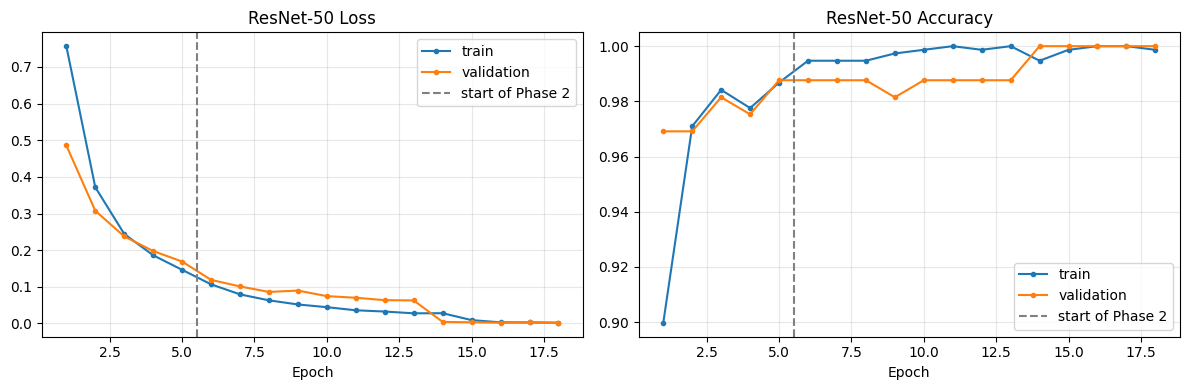

In [47]:
def plot_history(hist, phase_end, keys, titles, save_path):
    # Plot train/val curves for each metric pair with a line where Phase 2 starts.
    fig, axes = plt.subplots(1, len(keys), figsize=(6 * len(keys), 4))
    axes = np.atleast_1d(axes)
    for ax, (tr, va), title in zip(axes, keys, titles):
        ax.plot(range(1, len(hist[tr]) + 1), hist[tr], label="train", marker="o", ms=3)
        ax.plot(range(1, len(hist[va]) + 1), hist[va], label="validation", marker="o", ms=3)
        if len(phase_end) > 1:
            ax.axvline(phase_end[0] + 0.5, color="gray", ls="--", label="start of Phase 2")
        ax.set_xlabel("Epoch"); ax.set_title(title); ax.legend(); ax.grid(alpha=0.3)
    plt.tight_layout(); plt.savefig(save_path, dpi=150, bbox_inches="tight"); plt.show()

plot_history(cls_history, cls_phase_end,
             keys=[("train_loss", "val_loss"), ("train_acc", "val_acc")],
             titles=["ResNet-50 Loss", "ResNet-50 Accuracy"],
             save_path=os.path.join(RESULTS_DIR, "resnet_results.png"))

# Step 10: Evaluation on the Test Set
We now evaluate the best model on the **test set**, which was never used for training or model selection. Metrics:

* **Accuracy** = correct predictions / all predictions.
* **Precision** = of the images predicted as class *c*, how many really are *c*.
* **Recall** = of all images of class *c*, how many were found.
* **F1-score** = harmonic mean of precision and recall.
* **Confusion matrix** = rows are true classes, columns are predicted classes; off-diagonal cells are mistakes.

### Task 9 — Test-set predictions and metrics (Step 10)
* **(9a)** Complete `predict_loader`: for every batch run the model, take `argmax(1)` as the prediction and store true and predicted labels.
* **(9b)** Compute `resnet_train_acc`, `resnet_val_acc`, `resnet_test_acc` (use `accuracy_score`) and the **macro** `resnet_prec`, `resnet_rec`, `resnet_f1` on the **test set** (`precision_recall_fscore_support(..., average="macro")`).
* **(9c)** Print the `classification_report` of the test set.

In [48]:
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report
)


In [49]:
@torch.no_grad()
def predict_loader(model, loader):

    model.eval()

    y_true, y_pred = [], []

    for images, labels in loader:

        # Step 1: Move images to GPU/CPU
        images = images.to(device)

        # Step 2: Forward pass
        outputs = model(images)

        # Step 3: Get predicted class
        predictions = outputs.argmax(dim=1)

        # Step 4: Store true labels
        y_true.extend(labels.cpu().numpy())

        # Step 5: Store predicted labels
        y_pred.extend(predictions.cpu().numpy())

    return np.array(y_true), np.array(y_pred)


# Predictions for train, validation, and test
yt_tr, yp_tr = predict_loader(resnet, train_eval_loader)
yt_va, yp_va = predict_loader(resnet, val_loader)
yt_te, yp_te = predict_loader(resnet, test_loader)


# (9b) Accuracy for all three datasets
resnet_train_acc = accuracy_score(yt_tr, yp_tr)
resnet_val_acc = accuracy_score(yt_va, yp_va)
resnet_test_acc = accuracy_score(yt_te, yp_te)


# Macro precision, recall, and F1-score on test set
resnet_prec, resnet_rec, resnet_f1, _ = (
    precision_recall_fscore_support(
        yt_te,
        yp_te,
        average="macro",
        zero_division=0
    )
)


# Print evaluation results
print("===== ResNet-50 Evaluation =====")

print(f"Training Accuracy:   {resnet_train_acc:.4f}")
print(f"Validation Accuracy: {resnet_val_acc:.4f}")
print(f"Testing Accuracy:    {resnet_test_acc:.4f}")

print(f"Macro Precision: {resnet_prec:.4f}")
print(f"Macro Recall:    {resnet_rec:.4f}")
print(f"Macro F1-score:  {resnet_f1:.4f}")


# (9c) Classification report
print("\n===== Classification Report =====")

print(
    classification_report(
        yt_te,
        yp_te,
        labels=list(range(num_classes)),
        target_names=class_names,
        zero_division=0
    )
)

===== ResNet-50 Evaluation =====
Training Accuracy:   1.0000
Validation Accuracy: 1.0000
Testing Accuracy:    0.9939
Macro Precision: 0.9949
Macro Recall:    0.9949
Macro F1-score:  0.9948

===== Classification Report =====
                  precision    recall  f1-score   support

flower_class_051       1.00      0.97      0.99        39
flower_class_077       0.97      1.00      0.99        38
flower_class_046       1.00      1.00      1.00        30
flower_class_073       1.00      1.00      1.00        29
flower_class_089       1.00      1.00      1.00        27

        accuracy                           0.99       163
       macro avg       0.99      0.99      0.99       163
    weighted avg       0.99      0.99      0.99       163



### Task 10 — Confusion matrix and hardest class (Step 10)
1. Compute the confusion matrix `cm` of the test set (`confusion_matrix`).
2. Display it with `ConfusionMatrixDisplay` and save the figure as `results/resnet_confusion_matrix.png` (`plt.savefig(os.path.join(RESULTS_DIR, ...))`).
3. Compute the **accuracy of each class** (diagonal / row sum) and store the name of the worst class in `hardest_class`.

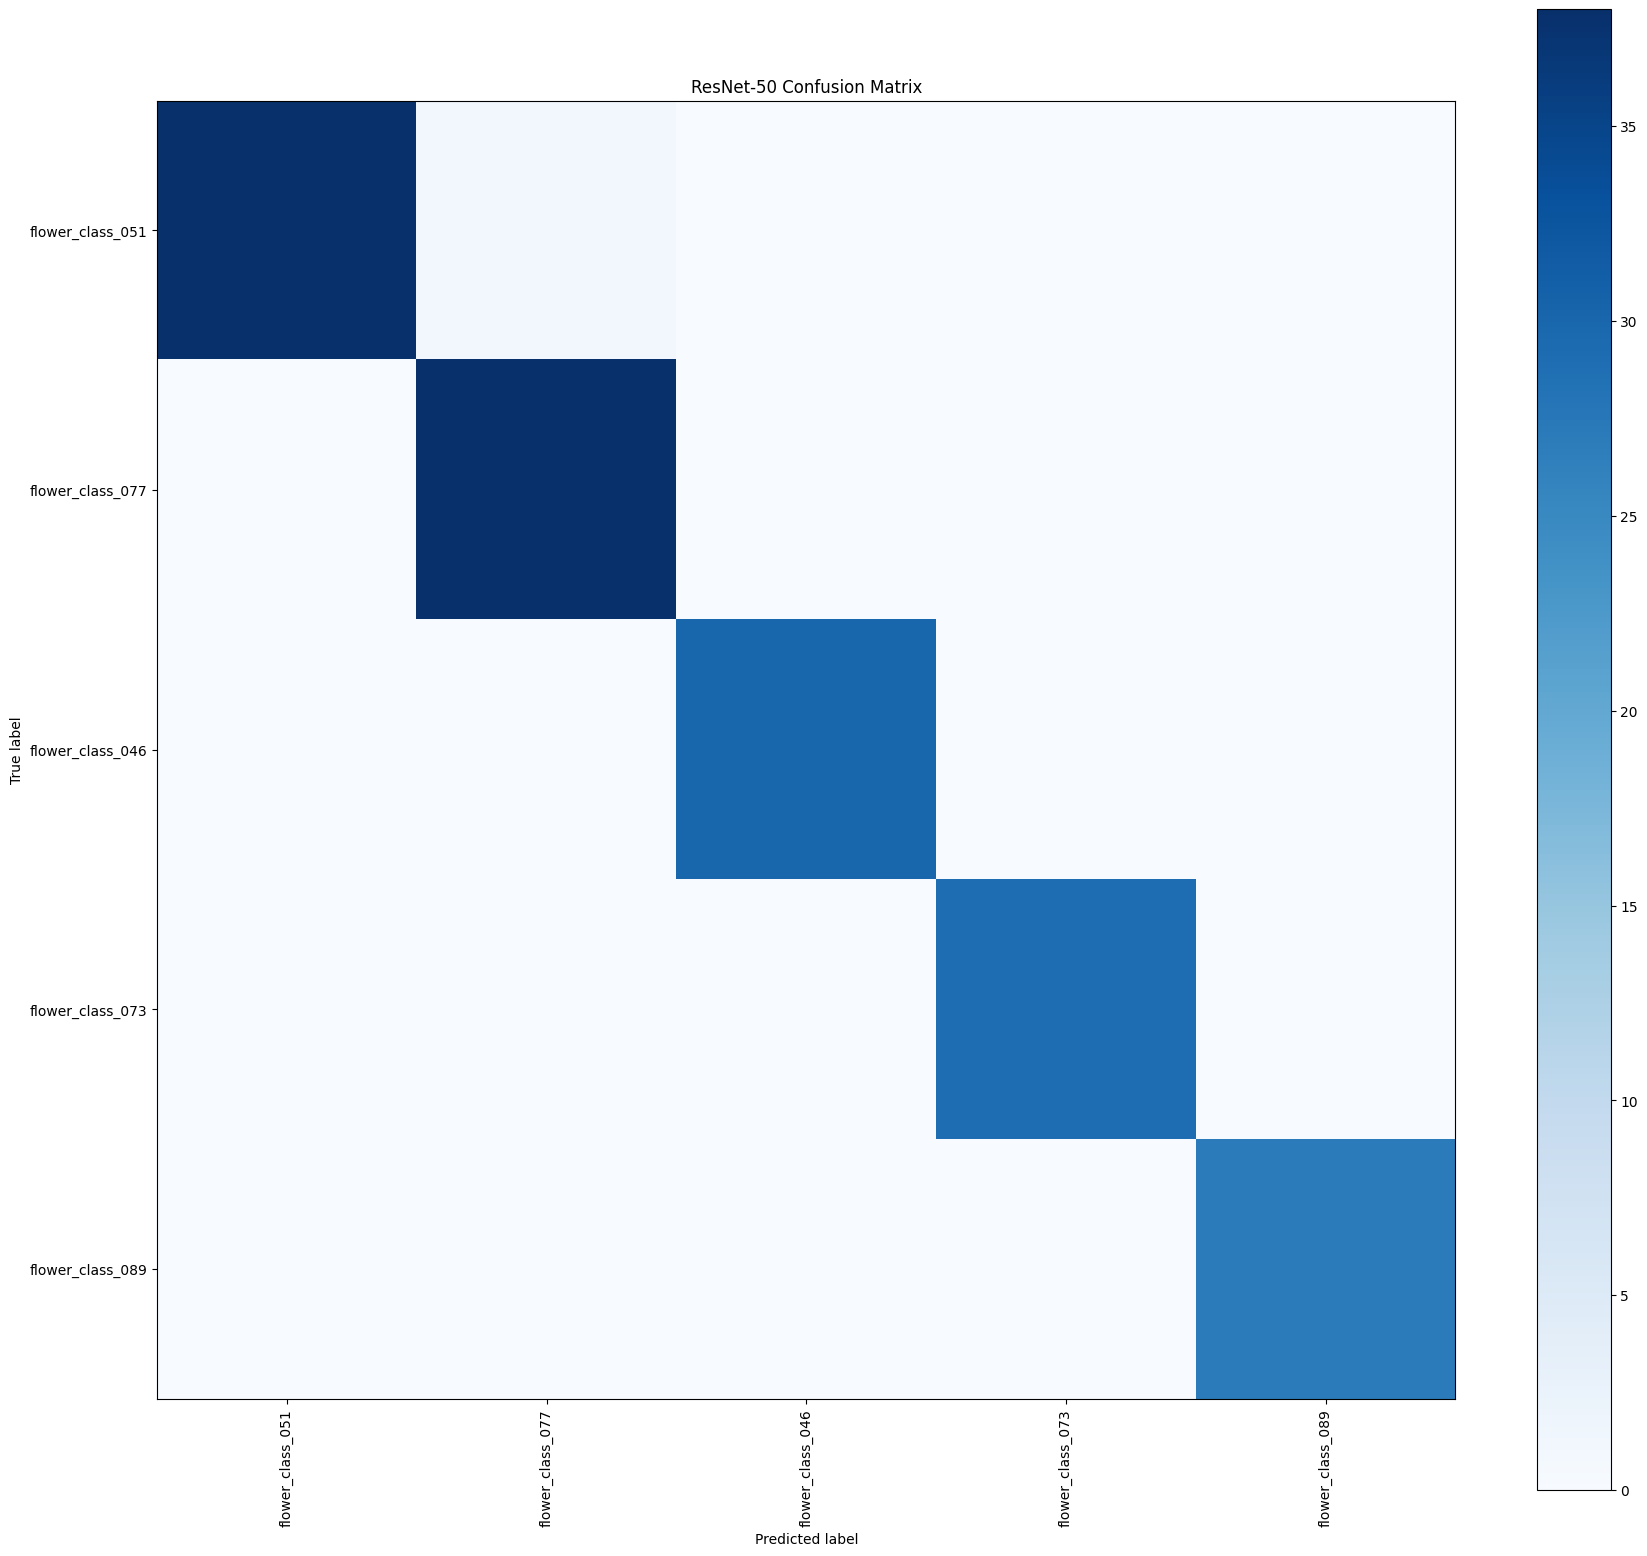

Hardest Class: flower_class_051
Class Accuracy: 97.44%


In [50]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# 1. Compute confusion matrix
cm = confusion_matrix(
    yt_te, yp_te,
    labels=np.arange(num_classes)
)

# 2. Display confusion matrix
fig, ax = plt.subplots(figsize=(18, 16))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

disp.plot(
    ax=ax,
    cmap="Blues",
    xticks_rotation=90,
    include_values=False
)

plt.title("ResNet-50 Confusion Matrix")
plt.tight_layout()

# Save the confusion matrix
os.makedirs(RESULTS_DIR, exist_ok=True)

plt.savefig(
    os.path.join(RESULTS_DIR, "resnet_confusion_matrix.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# 3. Calculate accuracy for each class
class_correct = np.diag(cm)
class_total = cm.sum(axis=1)

class_accuracy = np.divide(
    class_correct,
    class_total,
    out=np.full(num_classes, np.nan),
    where=class_total != 0
)

# Find hardest class
hardest_idx = np.nanargmin(class_accuracy)
hardest_class = class_names[hardest_idx]

print("Hardest Class:", hardest_class)
print(f"Class Accuracy: {class_accuracy[hardest_idx] * 100:.2f}%")

### Task 11 — Look at the mistakes (Step 10)
Find the indices where `yt_te != yp_te` and show up to **6 misclassified test images** with their true and predicted class. *Hint:* use `test_ds[i]` to get an image and the `denorm()` helper to display it.

**Observation:** why might the model confuse these images? ______________________________

Total misclassified images: 1


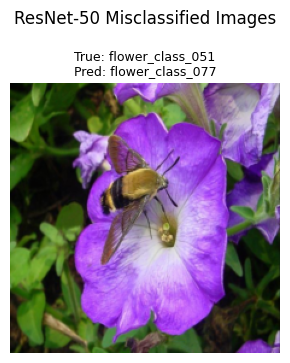

In [51]:
wrong_indices = np.where(yt_te != yp_te)[0]

print("Total misclassified images:", len(wrong_indices))

# 2. Display up to 6 incorrect predictions
num_show = min(6, len(wrong_indices))

if num_show > 0:

    fig, axes = plt.subplots(
        1, num_show,
        figsize=(3 * num_show, 4)
    )

    axes = np.atleast_1d(axes)

    for ax, i in zip(axes, wrong_indices[:num_show]):

        # Get image from test dataset
        img, label = test_ds[int(i)]

        # Undo normalization
        img = denorm(img)

        # Actual class
        true_class = class_names[int(yt_te[i])]

        # Predicted class
        predicted_class = class_names[int(yp_te[i])]

        # Display image
        ax.imshow(img)

        ax.set_title(
            f"True: {true_class}\nPred: {predicted_class}",
            fontsize=9
        )

        ax.axis("off")

    plt.suptitle("ResNet-50 Misclassified Images")
    plt.tight_layout()
    plt.show()

else:
    print("No misclassified images found!")

---
# PART B - U-Net Fine-Tuning (Segmentation)
---
# Step 11: Explore the Pet Segmentation Dataset
Segmentation assigns a label to **every pixel**. Each training example consists of:
```text
Image (RGB)  +  Ground-truth mask (same height/width)
```
The original masks are *trimaps*: `1 = pet`, `2 = background`, `3 = border`. We convert them to a **binary mask**: `pet (1 and 3) -> 1`, `background (2) -> 0`. First we verify that every image has a mask.

### Task 12 — Verify the image/mask pairs (Step 11)
* **(12a)** Fill `img_files` and `mask_files`: dictionaries mapping the **file-name stem** (name without extension, `os.path.splitext`) to the file name.
* **(12b)** Compute `pair_stems` = sorted list of stems present in **both** dictionaries and print: number of images, number of masks, number of valid pairs.
* **(12c)** Display **4 samples** (image on top, binary mask below). The function `load_binary_mask` is given.

**Report:** images = ______ , masks = ______ , valid pairs = ______

In [52]:
import os
import tarfile

# Your existing Google Drive archives
PET_IMG_ARCHIVE = "/content/drive/MyDrive/ann/oxford-iiit-pet/images.tar.gz"
PET_ANN_ARCHIVE = "/content/drive/MyDrive/ann/oxford-iiit-pet/annotations.tar.gz"

# Temporary local storage
PET_LOCAL_DIR = "/content/datasets/pets"

os.makedirs(PET_LOCAL_DIR, exist_ok=True)

# Extract image archive
with tarfile.open(PET_IMG_ARCHIVE, "r:gz") as tar:
    tar.extractall(PET_LOCAL_DIR, filter="data")

# Extract annotation archive
with tarfile.open(PET_ANN_ARCHIVE, "r:gz") as tar:
    tar.extractall(PET_LOCAL_DIR, filter="data")

# Update paths for subsequent notebook cells
PET_IMG_DIR = os.path.join(PET_LOCAL_DIR, "images")
PET_MASK_DIR = os.path.join(PET_LOCAL_DIR, "annotations", "trimaps")

print("Pet images directory:", PET_IMG_DIR)
print("Pet masks directory:", PET_MASK_DIR)

print("Images folder exists:", os.path.isdir(PET_IMG_DIR))
print("Masks folder exists:", os.path.isdir(PET_MASK_DIR))

Pet images directory: /content/datasets/pets/images
Pet masks directory: /content/datasets/pets/annotations/trimaps
Images folder exists: True
Masks folder exists: True


Number of images: 7390
Number of masks: 14780
Number of valid pairs: 7390


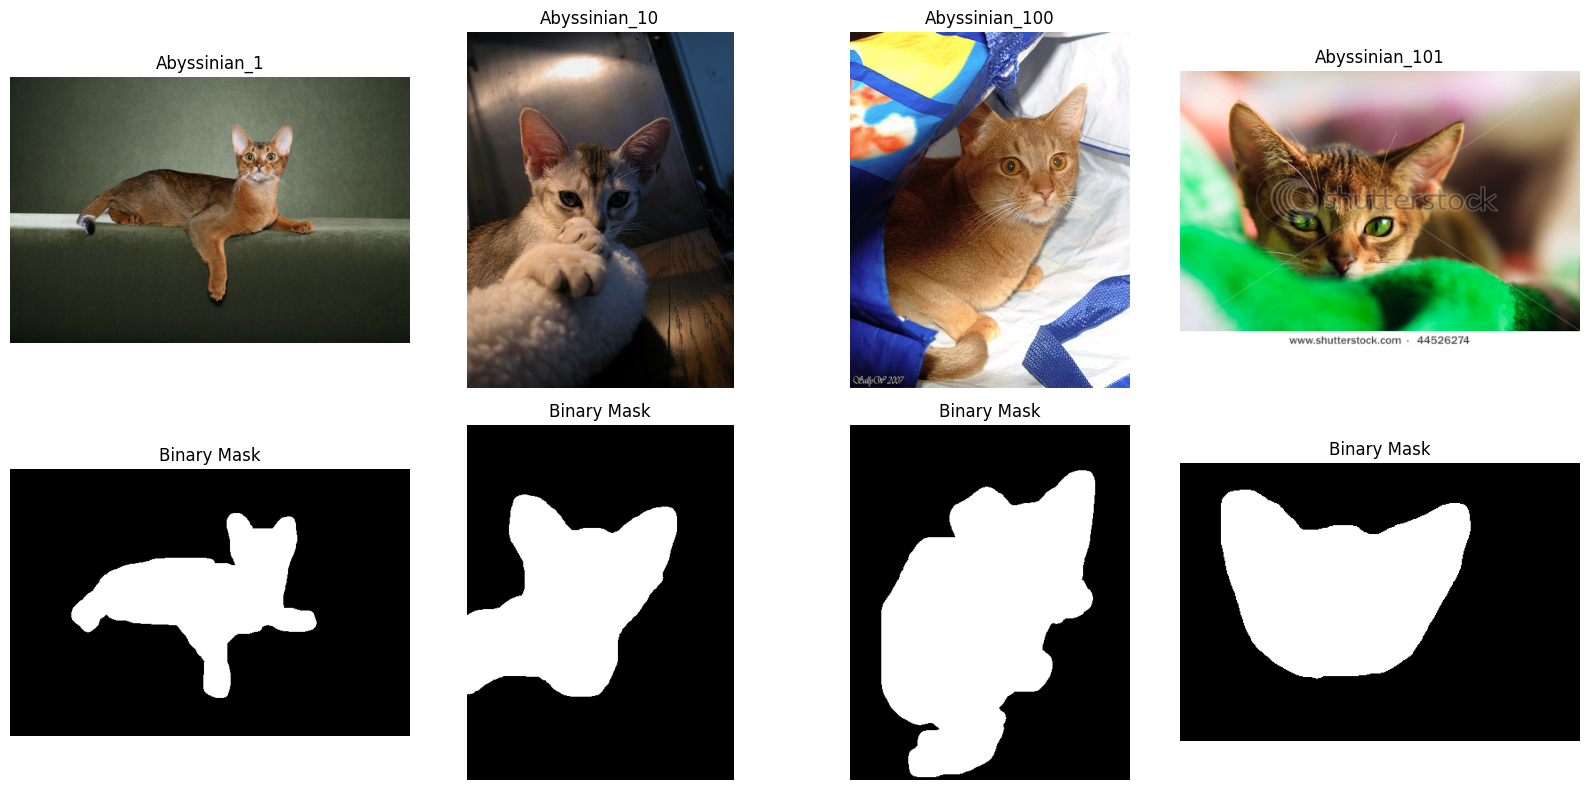

In [53]:
# (12a) Create dictionaries: filename stem -> filename

img_files = {
    os.path.splitext(f)[0]: f
    for f in os.listdir(PET_IMG_DIR)
    if f.lower().endswith((".jpg", ".jpeg"))
}

mask_files = {
    os.path.splitext(f)[0]: f
    for f in os.listdir(PET_MASK_DIR)
    if f.lower().endswith(".png")
}


# (12b) Find matching image/mask pairs

pair_stems = sorted(
    set(img_files.keys()) & set(mask_files.keys())
)

print("Number of images:", len(img_files))
print("Number of masks:", len(mask_files))
print("Number of valid pairs:", len(pair_stems))


# Given: Convert trimap to binary mask
def load_binary_mask(path):

    arr = np.array(
        Image.open(path).convert("L")
    )

    # Pet (1) and border (3) -> 255
    # Background (2) -> 0
    return (
        ((arr == 1) | (arr == 3)) * 255
    ).astype(np.uint8)


# (12c) Display four image/mask pairs

fig, axes = plt.subplots(2, 4, figsize=(16, 8))

for i, stem in enumerate(pair_stems[:4]):

    # Original image
    img_path = os.path.join(
        PET_IMG_DIR, img_files[stem]
    )

    # Corresponding segmentation mask
    mask_path = os.path.join(
        PET_MASK_DIR, mask_files[stem]
    )

    img = Image.open(img_path).convert("RGB")
    mask = load_binary_mask(mask_path)

    # Show RGB image
    axes[0, i].imshow(img)
    axes[0, i].set_title(stem)
    axes[0, i].axis("off")

    # Show binary mask
    axes[1, i].imshow(mask, cmap="gray", vmin=0, vmax=255)
    axes[1, i].set_title("Binary Mask")
    axes[1, i].axis("off")

plt.tight_layout()
plt.show()

# Step 12: Joint Image/Mask Preprocessing, Split and Loaders
> **Golden rule:** every *spatial* transformation (resize, flip, rotation) must be applied **identically** to the image **and** its mask:
> ```text
> Image ── Horizontal Flip ──► Augmented Image
> Mask  ── Horizontal Flip ──► Augmented Mask
> ```
Additional rules used below:
* Masks are resized/rotated with **nearest-neighbour** interpolation so values stay 0 or 1 (no blurred labels).
* Colour changes and normalization are applied to the **image only**.
* Images are resized to **256x256** (U-Net needs sizes divisible by 32).

### Task 13 — Segmentation dataset with joint transforms (Step 12)
Complete `__getitem__` of `PetSegDataset`. Remember the **golden rule**: *the same spatial transformation must be applied to the image and its mask.*

1. **Resize** both to `size x size` — the mask with `interpolation=TF.InterpolationMode.NEAREST`.
2. **If `self.train`:** random horizontal flip (probability 0.5, **same decision** for image and mask); random rotation by the **same angle** (use `TF.rotate`, mask with NEAREST); brightness/contrast change on the **image only**.
3. Image: `TF.to_tensor` then `TF.normalize(..., IMAGENET_MEAN, IMAGENET_STD)`. Mask: `TF.to_tensor` and convert to binary float `(mask > 0.5).float()`.

*Question:* why is NEAREST interpolation used for masks?

In [55]:
from torch.utils.data import Dataset
from torchvision.transforms import functional as TF
from torchvision.transforms import InterpolationMode

SEG_SIZE = 256

class PetSegDataset(Dataset):

    def __init__(self, stems, train=False, size=SEG_SIZE):
        self.stems = stems
        self.train = train
        self.size = size

    def __len__(self):
        return len(self.stems)

    def __getitem__(self, i):

        s = self.stems[i]

        # Load original image and binary segmentation mask
        image = Image.open(
            os.path.join(PET_IMG_DIR, img_files[s])
        ).convert("RGB")

        mask = Image.fromarray(
            load_binary_mask(
                os.path.join(PET_MASK_DIR, mask_files[s])
            )
        )

        # ----------------------------------
        # Step 1: Resize
        # ----------------------------------

        image = TF.resize(
            image,
            [self.size, self.size]
        )

        mask = TF.resize(
            mask,
            [self.size, self.size],
            interpolation=InterpolationMode.NEAREST
        )

        # ----------------------------------
        # Step 2: Joint augmentation
        # ----------------------------------

        if self.train:

            # Random horizontal flip (same decision)
            if random.random() < 0.5:
                image = TF.hflip(image)
                mask = TF.hflip(mask)

            # Random rotation (same angle)
            angle = random.uniform(-15, 15)

            image = TF.rotate(
                image,
                angle,
                interpolation=InterpolationMode.BILINEAR
            )

            mask = TF.rotate(
                mask,
                angle,
                interpolation=InterpolationMode.NEAREST
            )

            # Brightness and contrast changes (image only)
            image = ImageEnhance.Brightness(image).enhance(
                random.uniform(0.8, 1.2)
            )

            image = ImageEnhance.Contrast(image).enhance(
                random.uniform(0.8, 1.2)
            )

        # ----------------------------------
        # Step 3: Tensor conversion
        # ----------------------------------

        image = TF.to_tensor(image)

        image = TF.normalize(
            image,
            IMAGENET_MEAN,
            IMAGENET_STD
        )

        mask = TF.to_tensor(mask)

        # Convert mask to binary float (0 or 1)
        mask = (mask > 0.5).float()

        return image, mask

### Task 14 — Split and DataLoaders for segmentation (Step 12)
Shuffle `stems` (already done, reproducible) and split **70/15/15**. Create `seg_train_ds` (with `train=True`), `seg_val_ds`, `seg_test_ds`, then the three loaders `seg_train_loader` (shuffle), `seg_val_loader`, `seg_test_loader` with `SEG_BATCH = 8`. Print the size of each subset.

In [59]:
from PIL import Image, ImageEnhance

In [60]:

# Get all valid image/mask pairs
stems = list(pair_stems)

# Shuffle reproducibly
random.Random(SEED).shuffle(stems)

# -----------------------------------
# 70 / 15 / 15 split
# -----------------------------------

n = len(stems)

n_train = int(0.70 * n)
n_val = int(0.15 * n)

train_stems = stems[:n_train]

val_stems = stems[n_train:n_train + n_val]

test_stems = stems[n_train + n_val:]


# -----------------------------------
# Create segmentation datasets
# -----------------------------------

# Training dataset WITH augmentation
seg_train_ds = PetSegDataset(
    train_stems,
    train=True,
    size=SEG_SIZE
)

# Validation dataset WITHOUT augmentation
seg_val_ds = PetSegDataset(
    val_stems,
    train=False,
    size=SEG_SIZE
)

# Test dataset WITHOUT augmentation
seg_test_ds = PetSegDataset(
    test_stems,
    train=False,
    size=SEG_SIZE
)


# -----------------------------------
# Create DataLoaders
# -----------------------------------

SEG_BATCH = 8

seg_train_loader = DataLoader(
    seg_train_ds,
    batch_size=SEG_BATCH,
    shuffle=True,
    num_workers=2
)

seg_val_loader = DataLoader(
    seg_val_ds,
    batch_size=SEG_BATCH,
    shuffle=False,
    num_workers=2
)

seg_test_loader = DataLoader(
    seg_test_ds,
    batch_size=SEG_BATCH,
    shuffle=False,
    num_workers=2
)


# -----------------------------------
# Print dataset statistics
# -----------------------------------

print("Total valid pairs:", n)
print("Training samples:", len(seg_train_ds))
print("Validation samples:", len(seg_val_ds))
print("Testing samples:", len(seg_test_ds))

print("\nDataLoaders created successfully!")

Total valid pairs: 7390
Training samples: 5173
Validation samples: 1108
Testing samples: 1109

DataLoaders created successfully!


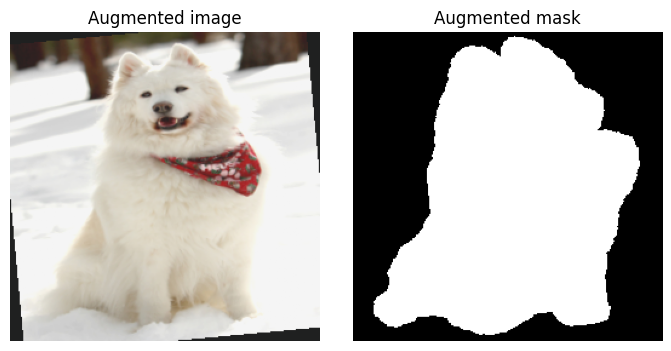

In [61]:
# Check that image and mask remain aligned after augmentation
im, mk = seg_train_ds[0]

fig, ax = plt.subplots(1, 2, figsize=(7, 3.5))

ax[0].imshow(denorm(im))
ax[0].set_title("Augmented image")
ax[0].axis("off")

ax[1].imshow(mk[0], cmap="gray")
ax[1].set_title("Augmented mask")
ax[1].axis("off")

plt.tight_layout()
plt.show()

# Step 13: U-Net Architecture and Model Creation
U-Net is an **encoder-decoder** network designed for pixel-wise prediction.

```text
                         U-NET (ResNet-50 encoder)

Input Image (256x256x3)
     │
     ▼
┌─────────────┐
│ Encoder 1   │───────────────┐         Encoder  : a ResNet-50 that extracts increasingly
└─────────────┘               │                    abstract features while halving the resolution
     │                        │
     ▼                        │         Skip     : encoder feature maps are copied (concatenated)
┌─────────────┐               │         connect.   to the decoder at the SAME resolution, giving the
│ Encoder 2   │──────────┐    │                    decoder the fine spatial detail lost by pooling
└─────────────┘          │    │
     │                   │    │         Bottleneck: deepest, most abstract representation
     ▼                   │    │
┌─────────────┐          │    │         Decoder  : up-sampling + convolution blocks that
│ Encoder 3   │─────┐    │    │                    rebuild the spatial resolution step by step
└─────────────┘     │    │    │
     │              │    │    │         Head     : 1x1 conv -> 1 channel (logit per pixel)
     ▼              │    │    │
┌─────────────┐     │    │    │
│ Bottleneck  │     │    │    │
└─────────────┘     │    │    │
     │              │    │    │
     ▼              │    │    │
┌─────────────┐     │    │    │
│ Decoder 3   │◄────┘    │    │
└─────────────┘          │    │
     │                   │    │
     ▼                   │    │
┌─────────────┐          │    │
│ Decoder 2   │◄─────────┘    │
└─────────────┘               │
     │                        │
     ▼                        │
┌─────────────┐               │
│ Decoder 1   │◄──────────────┘
└─────────────┘
     │
     ▼
Segmentation Mask (256x256x1)
```
**Why a pretrained encoder?** With only ~100 training images, a randomly initialized encoder would overfit. The ImageNet-pretrained ResNet-50 encoder already extracts good edges/textures/shapes, so we mainly have to train the **decoder** and gently adapt the encoder.

**Fine-tuning strategy** (same idea as ResNet): Phase 1 freeze the encoder and train decoder + head; Phase 2 unfreeze the last encoder stages (`layer3`, `layer4`) with a smaller learning rate.

In [62]:
# U-Net with a pretrained ResNet-50 encoder, 1 output channel (binary mask), outputs raw logits
unet = smp.Unet(
    encoder_name="resnet50",       # ResNet-50 backbone as the encoder
    encoder_weights="imagenet",    # pretrained on ImageNet
    in_channels=3,                 # RGB
    classes=1,                     # binary segmentation: 1 logit per pixel
).to(device)

total, trainable = count_params(unet)
enc_total = sum(p.numel() for p in unet.encoder.parameters())
print(f"Total parameters: {total:,} | Encoder: {enc_total:,} | Decoder + head: {total - enc_total:,}")

# Quick shape test: input [2,3,256,256] -> output must be [2,1,256,256]
with torch.no_grad():
    print("Output shape:", unet(torch.randn(2, 3, SEG_SIZE, SEG_SIZE).to(device)).shape)

config.json:   0%|          | 0.00/156 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  102MB            

model.safetensors: downloading bytes:           |  0.00B            

Total parameters: 32,521,105 | Encoder: 23,508,032 | Decoder + head: 9,013,073
Output shape: torch.Size([2, 1, 256, 256])


# Step 14: Loss Function and Metrics

### Loss = BCE + Dice
* **Binary Cross-Entropy (BCE)** treats every pixel as an independent classification problem.
* **Dice loss** `= 1 - Dice` directly optimizes the *overlap* between prediction and ground truth. It is robust to **class imbalance** (the pet may cover only a small part of the image, so "predict everything background" would give a low BCE but a bad Dice).

### Metrics
```text
Dice = 2 x |Prediction ∩ Ground Truth| / ( |Prediction| + |Ground Truth| )

IoU  =     |Prediction ∩ Ground Truth| /   |Prediction ∪ Ground Truth|
```
Both range from 0 (no overlap) to 1 (perfect). IoU is always <= Dice for the same prediction. Predicted probabilities are thresholded at 0.5 for the metrics.

### Task 15 — Segmentation loss and metrics (Step 14)
Implement the following functions. Inputs are **logits** (`[B,1,H,W]`) and binary `targets` of the same shape. Sum over the dimensions `(1, 2, 3)` to get one value per image, then average over the batch. Use `eps=1e-6` to avoid division by zero.

| Function | Definition | Notes |
|---|---|---|
| `dice_loss` | `1 - mean( (2*inter + eps) / (union + eps) )` | uses **probabilities** `torch.sigmoid(logits)`; `union = sum(p) + sum(target)` |
| `seg_loss` | `BCE + Dice loss` | use `bce_loss_fn` |
| `dice_score` | same formula as above | uses the **thresholded** prediction `(sigmoid > 0.5).float()`; return `.item()` |
| `iou_score` | `(inter + eps) / (union + eps)` | here `union = sum(pred) + sum(target) - inter`; return `.item()` |

```text
Dice = 2 x |Prediction ∩ Ground Truth| / ( |Prediction| + |Ground Truth| )
IoU  =     |Prediction ∩ Ground Truth| /   |Prediction ∪ Ground Truth|
```

In [63]:
# BCE loss for binary segmentation
bce_loss_fn = nn.BCEWithLogitsLoss()

# (15a) Dice Loss
def dice_loss(logits, targets, eps=1e-6):

    probs = torch.sigmoid(logits)

    intersection = (probs * targets).sum(dim=(1, 2, 3))

    union = probs.sum(dim=(1, 2, 3)) + targets.sum(dim=(1, 2, 3))

    dice = (2 * intersection + eps) / (union + eps)

    return 1 - dice.mean()


# (15b) Combined BCE + Dice Loss
def seg_loss(logits, targets):

    bce = bce_loss_fn(logits, targets)

    dice = dice_loss(logits, targets)

    return bce + dice


# (15c) Dice Score
def dice_score(logits, targets, eps=1e-6):

    preds = (torch.sigmoid(logits) > 0.5).float()

    intersection = (preds * targets).sum(dim=(1, 2, 3))

    union = preds.sum(dim=(1, 2, 3)) + targets.sum(dim=(1, 2, 3))

    dice = (2 * intersection + eps) / (union + eps)

    return dice.mean().item()


# (15d) IoU Score
def iou_score(logits, targets, eps=1e-6):

    preds = (torch.sigmoid(logits) > 0.5).float()

    intersection = (preds * targets).sum(dim=(1, 2, 3))

    union = (
        preds.sum(dim=(1, 2, 3))
        + targets.sum(dim=(1, 2, 3))
        - intersection
    )

    iou = (intersection + eps) / (union + eps)

    return iou.mean().item()


# (Given) Pixel Accuracy
def pixel_accuracy(logits, targets):

    return (
        (torch.sigmoid(logits) > 0.5).float()
        == targets
    ).float().mean().item()

### Task 16 — One segmentation epoch (Step 14)
Complete `run_epoch_seg`: for every batch move data to `device`, forward pass, `loss = seg_loss(logits, masks)`, **if training** `zero_grad -> backward -> step`, and accumulate the **loss, Dice and IoU** weighted by the batch size `k = images.size(0)`. Return `(avg loss, avg dice, avg iou)`.

In [64]:
def run_epoch_seg(model, loader, optimizer=None):

    training = optimizer is not None
    model.train(training)

    if training:
        keep_frozen_bn_eval(model)

    tot_loss = tot_dice = tot_iou = n = 0

    with torch.set_grad_enabled(training):

        for images, masks in loader:

            # Step 1: Move images and masks to GPU/CPU
            images = images.to(device)
            masks = masks.to(device)

            # Step 2: Clear previous gradients
            if training:
                optimizer.zero_grad()

            # Step 3: Forward pass
            logits = model(images)

            # Step 4: Calculate segmentation loss
            loss = seg_loss(logits, masks)

            # Step 5: Backpropagation and optimizer update
            if training:
                loss.backward()
                optimizer.step()

            # Step 6: Calculate Dice and IoU
            dice = dice_score(logits.detach(), masks)
            iou = iou_score(logits.detach(), masks)

            # Step 7: Accumulate batch-weighted metrics
            b = images.size(0)

            tot_loss += loss.item() * b
            tot_dice += dice * b
            tot_iou += iou * b

            n += b

    return tot_loss / n, tot_dice / n, tot_iou / n

In [65]:
# Given: training manager (keeps the checkpoint with the best validation Dice)
seg_history = {"train_loss": [], "val_loss": [], "train_dice": [], "val_dice": [], "train_iou": [], "val_iou": []}
seg_phase_end = []

def fit_seg(model, optimizer, epochs, ckpt_path, scheduler=None):
    best = 0.0
    for ep in range(1, epochs + 1):
        t0 = time.time()
        trl, trd, tri = run_epoch_seg(model, seg_train_loader, optimizer)
        val, vad, vai = run_epoch_seg(model, seg_val_loader)
        if scheduler: scheduler.step()
        for k, v in zip(seg_history, [trl, val, trd, vad, tri, vai]):
            seg_history[k].append(v)
        if vad >= best:
            best = vad
            torch.save(model.state_dict(), ckpt_path)
        print(f"Epoch {ep:02d}/{epochs} | train loss {trl:.4f} dice {trd:.3f} | "
              f"val loss {val:.4f} dice {vad:.3f} iou {vai:.3f} | {time.time()-t0:.1f}s")
    model.load_state_dict(torch.load(ckpt_path, map_location=device))
    seg_phase_end.append(len(seg_history["val_dice"]))
    return best

# Step 15: Phase 1 - Train the Decoder (Frozen Encoder)
The pretrained ResNet-50 encoder is frozen; only the randomly initialized decoder and segmentation head are trained (lr = 1e-3).

### Task 17 — U-Net Phase 1: freeze the encoder (Step 15)
* **(17a)** Freeze **all** parameters of `unet.encoder`.
* **(17b)** Create `AdamW` over the trainable parameters (`lr=1e-3`, `weight_decay=1e-4`).

**Report:** trainable parameters = ______ ; best validation Dice after Phase 1 = ______

In [66]:
import torch.optim as optim


In [68]:
# (17a) Freeze the encoder
for param in unet.encoder.parameters():
    param.requires_grad = False

# Keep decoder and segmentation head trainable
for name, param in unet.named_parameters():
    if not name.startswith("encoder."):
        param.requires_grad = True

# Count parameters
total, trainable = count_params(unet)

print(f"Phase 1 -> trainable parameters: {trainable:,} of {total:,}")


# (17b) AdamW optimizer over trainable parameters
optimizer = optim.AdamW(
    filter(lambda p: p.requires_grad, unet.parameters()),
    lr=1e-3,
    weight_decay=1e-4
)

# Ensure checkpoint directory exists
os.makedirs(CKPT_DIR, exist_ok=True)

# Train for 5 epochs
unet_phase1_best = fit_seg(
    unet,
    optimizer,
    epochs=5,
    ckpt_path=os.path.join(CKPT_DIR, "unet_phase1.pth")
)

print(f"Best validation Dice after Phase 1: {unet_phase1_best:.3f}")

Phase 1 -> trainable parameters: 9,013,073 of 32,521,105
Epoch 01/5 | train loss 0.2224 dice 0.934 | val loss 0.1976 dice 0.942 iou 0.897 | 132.0s
Epoch 02/5 | train loss 0.1898 dice 0.943 | val loss 0.1834 dice 0.945 iou 0.903 | 122.6s
Epoch 03/5 | train loss 0.1776 dice 0.947 | val loss 0.1913 dice 0.948 iou 0.907 | 119.4s
Epoch 04/5 | train loss 0.1675 dice 0.949 | val loss 0.1765 dice 0.948 iou 0.907 | 118.7s
Epoch 05/5 | train loss 0.1613 dice 0.951 | val loss 0.1758 dice 0.948 iou 0.908 | 122.0s
Best validation Dice after Phase 1: 0.948


# Step 16: Phase 2 - Fine-Tune the Encoder
We unfreeze the last two encoder stages (`layer3`, `layer4`). They get a small learning rate (1e-4); the decoder and head continue with a moderate one (3e-4). Different learning rates per parameter group are called **discriminative learning rates**.

### Task 18 — U-Net Phase 2: fine-tune the encoder (Step 16)
* **(18a)** Unfreeze `unet.encoder.layer3` and `unet.encoder.layer4`.
* **(18b)** Build an `AdamW` optimizer with **two parameter groups** (*discriminative learning rates*): the unfrozen encoder layers with `lr=1e-4`, and all the other trainable parameters (decoder + segmentation head) with `lr=3e-4`.
  *Hint:* collect the encoder parameters in a list, then take the remaining trainable parameters whose `id()` is not in the encoder list.

**Report:** best validation Dice after Phase 2 = ______ ; improvement over Phase 1? ______

In [69]:
# (18a) Unfreeze layer3 and layer4 of the encoder
for param in unet.encoder.layer3.parameters():
    param.requires_grad = True

for param in unet.encoder.layer4.parameters():
    param.requires_grad = True

# Count parameters
total, trainable = count_params(unet)

print(f"Phase 2 -> trainable parameters: {trainable:,} of {total:,}")


# (18b) Optimizer with two parameter groups

# Collect trainable encoder parameters
encoder_params = list(unet.encoder.layer3.parameters()) + \
                 list(unet.encoder.layer4.parameters())

encoder_params = [p for p in encoder_params if p.requires_grad]

# Identify encoder parameters
encoder_param_ids = {id(p) for p in encoder_params}

# Collect remaining trainable parameters (decoder + head)
decoder_params = [
    p for p in unet.parameters()
    if p.requires_grad and id(p) not in encoder_param_ids
]

# AdamW optimizer with different learning rates
optimizer = optim.AdamW(
    [
        {
            "params": encoder_params,
            "lr": 1e-4
        },
        {
            "params": decoder_params,
            "lr": 3e-4
        }
    ],
    weight_decay=1e-4
)


# Cosine scheduler (given)
scheduler = optim.lr_scheduler.CosineAnnealingLR(
    optimizer,
    T_max=15
)

# Train Phase 2 for 5 epochs
unet_phase2_best = fit_seg(
    unet,
    optimizer,
    epochs=5,
    ckpt_path=os.path.join(CKPT_DIR, "unet_best.pth"),
    scheduler=scheduler
)

print(f"Best validation Dice after Phase 2: {unet_phase2_best:.3f}")

# Compare Phase 1 and Phase 2
improvement = unet_phase2_best - unet_phase1_best

print(f"Phase 1 Dice: {unet_phase1_best:.3f}")
print(f"Phase 2 Dice: {unet_phase2_best:.3f}")
print(f"Improvement over Phase 1: {improvement:+.3f}")

Phase 2 -> trainable parameters: 31,076,177 of 32,521,105
Epoch 01/5 | train loss 0.1854 dice 0.944 | val loss 0.1833 dice 0.947 iou 0.906 | 155.0s
Epoch 02/5 | train loss 0.1671 dice 0.949 | val loss 0.1781 dice 0.948 iou 0.908 | 152.0s
Epoch 03/5 | train loss 0.1550 dice 0.953 | val loss 0.1712 dice 0.949 iou 0.910 | 150.1s
Epoch 04/5 | train loss 0.1481 dice 0.954 | val loss 0.1731 dice 0.949 iou 0.910 | 153.2s
Epoch 05/5 | train loss 0.1409 dice 0.956 | val loss 0.1748 dice 0.950 iou 0.911 | 158.9s
Best validation Dice after Phase 2: 0.950
Phase 1 Dice: 0.948
Phase 2 Dice: 0.950
Improvement over Phase 1: +0.002


# Step 17: Evaluation and Visualization
Final evaluation on the **test set** (Dice, IoU, pixel accuracy), training curves, and a visual comparison `Input | Ground truth | Prediction | Overlay`.

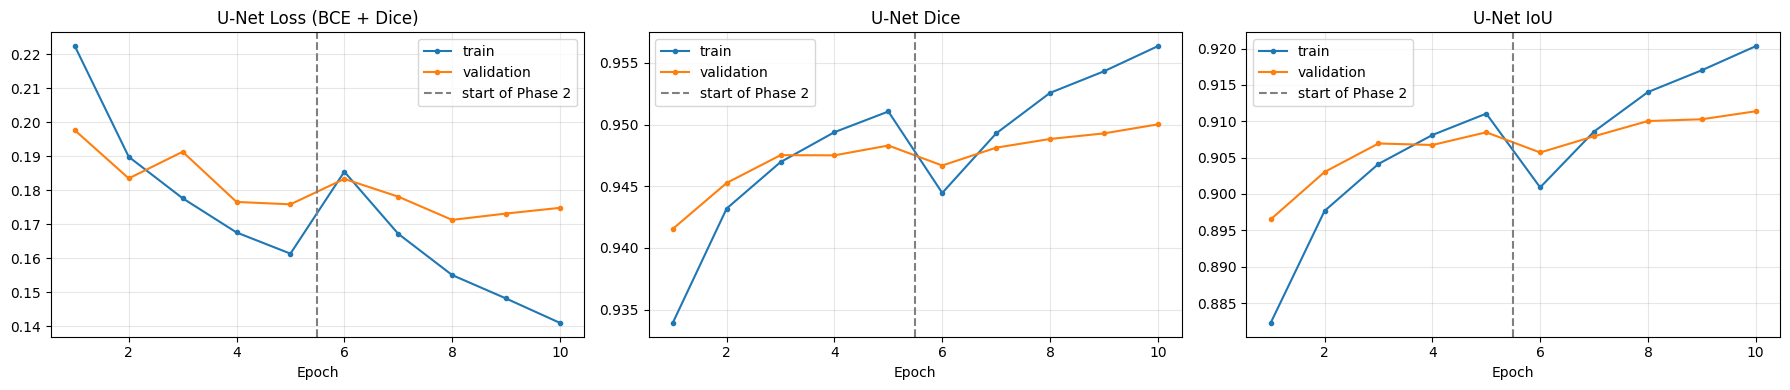

In [70]:
# Given: training curves of the U-Net
plot_history(seg_history, seg_phase_end,
             keys=[("train_loss", "val_loss"), ("train_dice", "val_dice"), ("train_iou", "val_iou")],
             titles=["U-Net Loss (BCE + Dice)", "U-Net Dice", "U-Net IoU"],
             save_path=os.path.join(RESULTS_DIR, "unet_curves.png"))

### Task 19 — Evaluate the U-Net (Step 17)
Write `evaluate_seg(model, loader)`: loop over the loader in eval mode (no gradients), accumulate `seg_loss`, `dice_score`, `iou_score` and `pixel_accuracy` (weighted by batch size) and **return** `(loss, dice, iou, pixel_acc)` averages. The calls below use it to produce the validation and test results.

In [71]:
from torch.utils.data import DataLoader


In [72]:
# (19a) Evaluate segmentation model
@torch.no_grad()
def evaluate_seg(model, loader):

    model.eval()

    total_loss = 0.0
    total_dice = 0.0
    total_iou = 0.0
    total_pixel_acc = 0.0
    n = 0

    for images, masks in loader:

        # Step 1: Move images and masks to device
        images = images.to(device)
        masks = masks.to(device)

        # Step 2: Forward pass
        logits = model(images)

        # Step 3: Calculate metrics
        loss = seg_loss(logits, masks)
        dice = dice_score(logits, masks)
        iou = iou_score(logits, masks)
        pix_acc = pixel_accuracy(logits, masks)

        # Step 4: Get batch size
        b = images.size(0)

        # Step 5: Accumulate weighted metrics
        total_loss += loss.item() * b
        total_dice += dice * b
        total_iou += iou * b
        total_pixel_acc += pix_acc * b

        n += b

    # Step 6: Return average metrics
    return (
        total_loss / n,
        total_dice / n,
        total_iou / n,
        total_pixel_acc / n
    )


# Given: Evaluation calls

# Training loss without augmentation
train_noaug = DataLoader(
    PetSegDataset(seg_train_ds.stems, train=False),
    batch_size=SEG_BATCH,
    shuffle=False,
    num_workers=2
)

unet_train_loss = evaluate_seg(unet, train_noaug)[0]

# Validation results
unet_val_loss, unet_val_dice, unet_val_iou, _ = evaluate_seg(
    unet, seg_val_loader
)

# Test results
unet_test_loss, unet_test_dice, unet_test_iou, unet_test_acc = evaluate_seg(
    unet, seg_test_loader
)

# Print results
print(f"Training loss: {unet_train_loss:.4f}")

print(
    f"Validation: loss {unet_val_loss:.4f} | "
    f"Dice {unet_val_dice:.4f} | "
    f"IoU {unet_val_iou:.4f}"
)

print(
    f"TEST: loss {unet_test_loss:.4f} | "
    f"Dice {unet_test_dice:.4f} | "
    f"IoU {unet_test_iou:.4f} | "
    f"pixel acc {unet_test_acc:.4f}"
)

Training loss: 0.1279
Validation: loss 0.1748 | Dice 0.9500 | IoU 0.9114
TEST: loss 0.1568 | Dice 0.9512 | IoU 0.9122 | pixel acc 0.9645


### Task 20 — Visualize the U-Net predictions (Step 17)
Take one batch from `seg_test_loader`, predict masks for up to **5 samples** (sigmoid, threshold 0.5) and display, for each sample, **four columns**: `Input | Ground truth | Prediction | Overlay`. In the overlay, colour the predicted pet region in red on top of the image. Save the figure as `results/unet_predictions.png`.

**Observation:** in which regions does the U-Net make mistakes (boundaries, thin parts, similar colours)? ______________________________

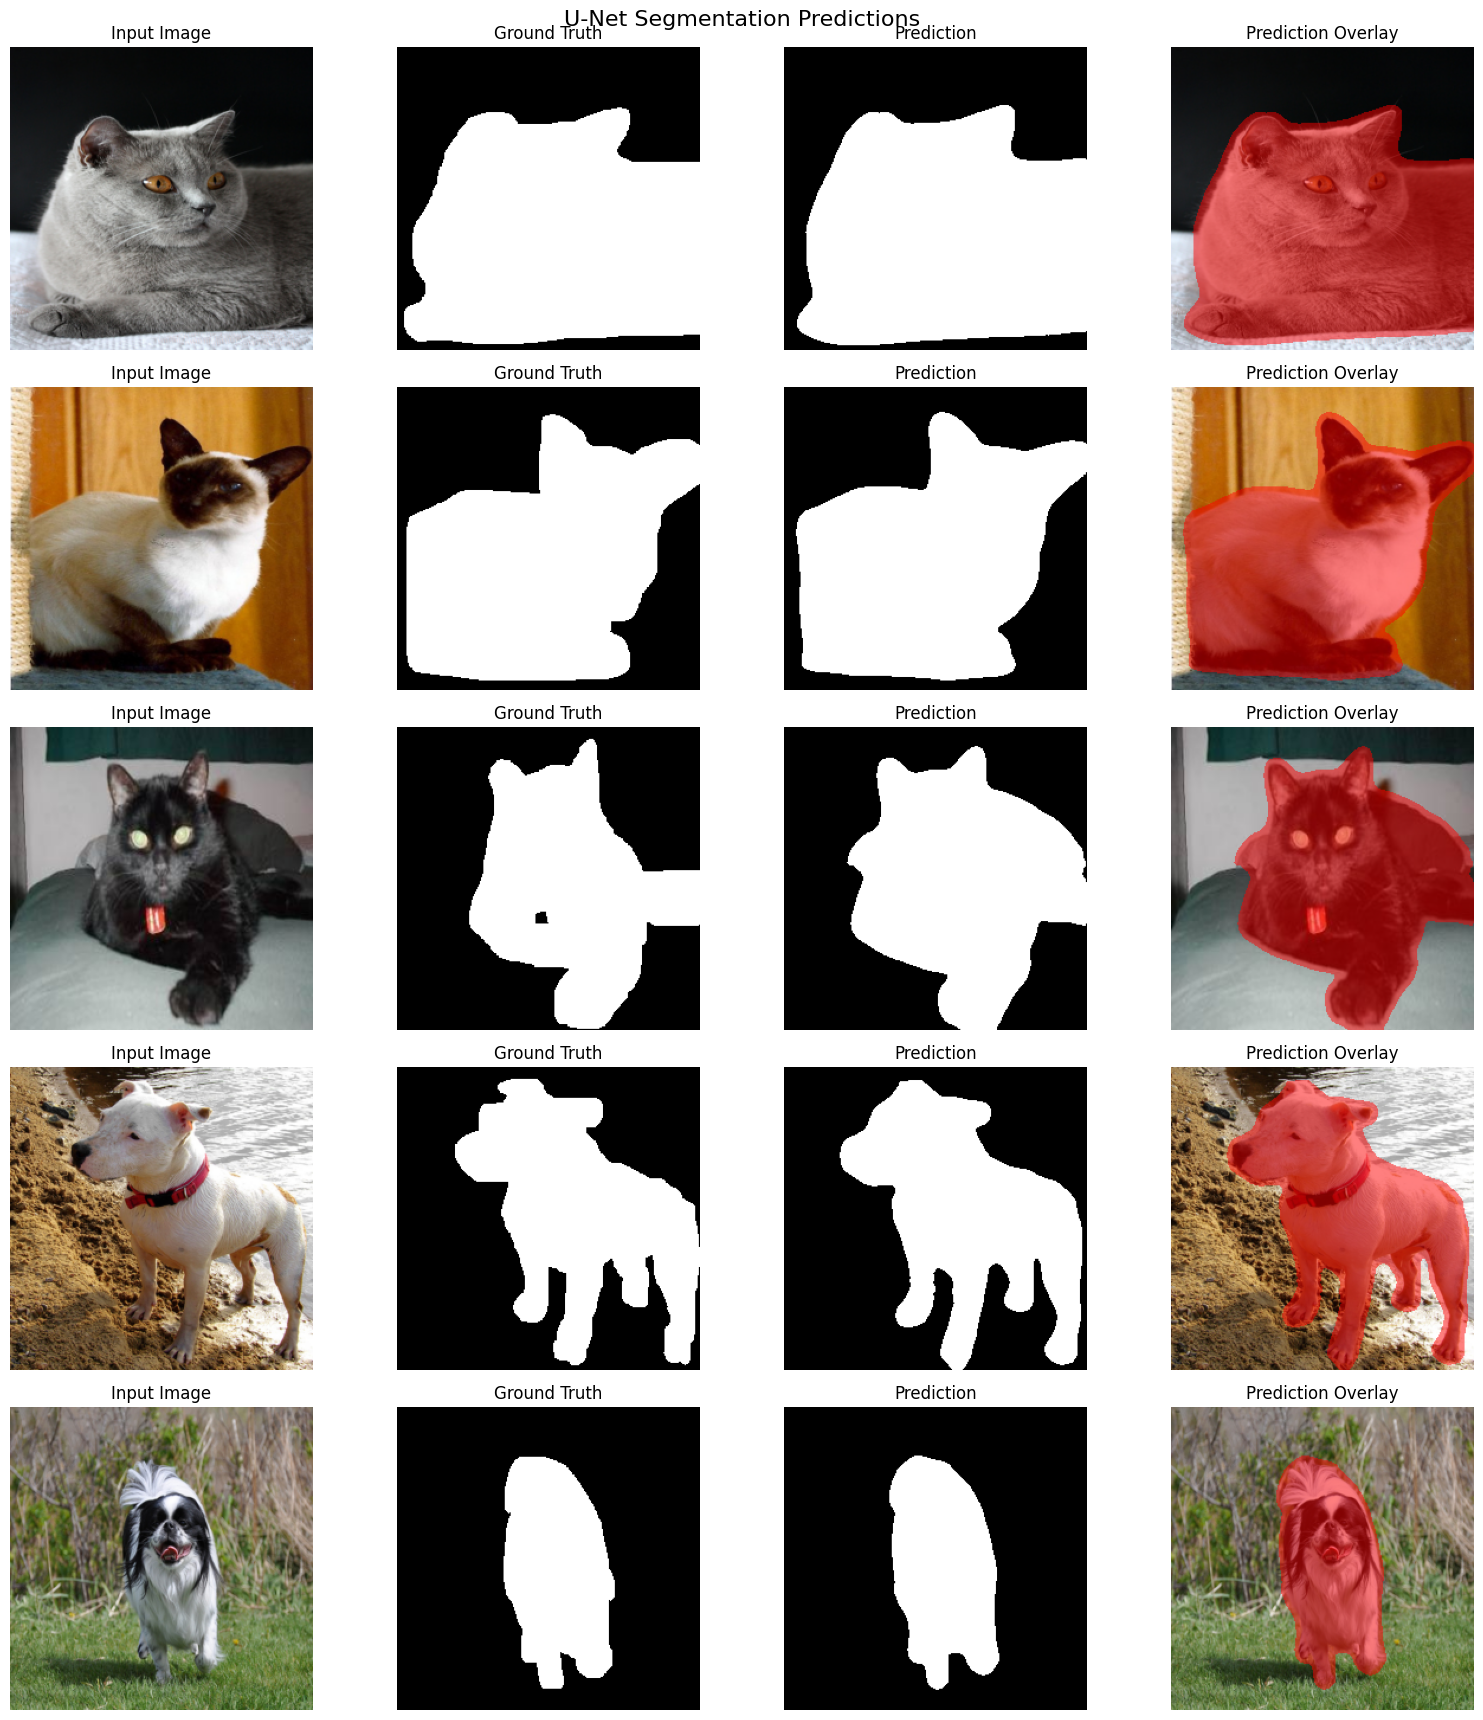

Predictions saved to: /content/results/unet_predictions.png


In [73]:

# Set U-Net to evaluation mode
unet.eval()

images, masks = next(iter(seg_test_loader))

images = images.to(device)

with torch.no_grad():
    logits = unet(images)

    probs = torch.sigmoid(logits)

    predictions = (probs > 0.5).float()

num_samples = min(5, images.size(0))

# 5 rows and 4 columns
fig, axes = plt.subplots(
    num_samples,
    4,
    figsize=(16, num_samples * 3.5),
    squeeze=False
)

for i in range(num_samples):

    # Original image (reverse normalization)
    img = denorm(images[i]).copy()

    # Ground truth mask
    true_mask = masks[i, 0].cpu().numpy()

    # Predicted mask
    pred_mask = predictions[i, 0].cpu().numpy()

    # red overlay
    overlay = img.copy()

    # predicted pet pixels in red
    red = np.array([1.0, 0.0, 0.0])
    overlay[pred_mask > 0.5] = (
        0.5 * overlay[pred_mask > 0.5]
        + 0.5 * red
    )

    # Column 1: Original input
    axes[i, 0].imshow(img)
    axes[i, 0].set_title("Input Image")

    # Column 2: Ground truth
    axes[i, 1].imshow(
        true_mask,
        cmap="gray",
        vmin=0,
        vmax=1
    )
    axes[i, 1].set_title("Ground Truth")

    # Column 3: Predicted mask
    axes[i, 2].imshow(
        pred_mask,
        cmap="gray",
        vmin=0,
        vmax=1
    )
    axes[i, 2].set_title("Prediction")

    axes[i, 3].imshow(overlay)
    axes[i, 3].set_title("Prediction Overlay")

    for j in range(4):
        axes[i, j].axis("off")

plt.suptitle(
    "U-Net Segmentation Predictions",
    fontsize=16
)

plt.tight_layout()

# Save results
os.makedirs(RESULTS_DIR, exist_ok=True)

save_path = os.path.join(
    RESULTS_DIR,
    "unet_predictions.png"
)

plt.savefig(
    save_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Predictions saved to:", save_path)

## Results Tables (fill in with YOUR results)
| ResNet-50 Metric | Result |
| --- | ---: |
| Training Accuracy | 1 |
| Validation Accuracy | 1 |
| Test Accuracy | 0.9939 |
| Precision (macro) | 0.9949 |
| Recall (macro) | 0.9949 |
| F1-score (macro) | 0.9948 |

| U-Net Metric | Result |
| --- | ---: |
| Training Loss | 0.1279 |
| Validation Loss | 0.1748 |
| Test Dice | 0.9500 |
| Test IoU | 0.9114 |

| Model | Dataset | Task | Main Metric | Result |
| --- | --- | --- | --- | ---: |
| ResNet-50 | flowers dataset | Classification | Accuracy | 99.80 |
| U-Net | oxford pet dataset | Segmentation | Dice / IoU | 0.9500/0.9114 |

---
# Uploading the Assignment to GitHub (Detailed Procedure)

**GitHub** is a website that stores your project in a *repository* ("repo") with full version history.

## 1. What to upload
```text
resnet-unet-finetuning-assignment/
│
├── notebook/
│   └── assignment_resnet_unet.ipynb      <- this notebook, saved WITH outputs
│
├── results/
│   ├── resnet_results.png
│   ├── resnet_confusion_matrix.png
│   ├── unet_predictions.png
│   ├── unet_curves.png
│   └── (csv tables)
│

```
**Do NOT upload:** the datasets, or the trained weights (`*.pth`). GitHub rejects any single file larger than **100 MB**, and a U-Net with a ResNet-50 encoder is larger than that. Put the dataset link in the README and share the weights through a Google Drive link if required.

## 2. Prepare the files from Colab
1. Make sure the notebook was run **top to bottom** so that all outputs/figures are visible.
2. **Download the notebook:** `File -> Download -> Download .ipynb`.
3. **Download the results:** your figures are in `/content/results` and in `MyDrive/DL_Assignment/results` (open the Colab *Files* sidebar, or download them from Drive).


## 3.Create a GitHub account and repository
1. Go to **https://github.com** -> **Sign up** (skip if you already have an account) and verify your e-mail.
2. Click the **+** icon (top right) -> **New repository**.
3. **Repository name:** `[Roll_no]-assignment`
4. **Description:** *Fine-tuning ResNet-50 and U-Net on small image datasets*.
5. Choose **Public** (or Private and add your instructor as a collaborator: *Settings -> Collaborators*).
6. then click **Create repository**.
## 4 - Command line (Git)
Run this on your computer in the project folder (install Git from https://git-scm.com).

```bash
# one-time configuration (use your GitHub name and e-mail)
git config --global user.name  "Your Name"
git config --global user.email "you@example.com"

# create the local repository and make the first commit
git init
git add .
git commit -m "Complete ResNet and U-Net assignment"
git branch -M main

# connect to GitHub and upload
git remote add origin https://github.com/<your-username>/resnet-unet-finetuning-assignment.git
git push -u origin main
```
* GitHub **no longer accepts your account password** for `git push`. When asked for a password, paste a **Personal Access Token**: GitHub -> *Settings -> Developer settings -> Personal access tokens -> Tokens (classic) -> Generate new token*, tick the `repo` scope, copy the token (it is shown only once). Never share a token or write it inside the notebook.
* If you created the repo with a README, run `git pull origin main --allow-unrelated-histories` once before pushing.
* To update later: `git add .` -> `git commit -m "message"` -> `git push`.
